# Stage 1 · WP1: Data and Topic Analysis
| **Track** | Open models |

| | |
|---|---|
| **Work package** | WP1 — objective, data collection and cleaning, text preprocessing, exploratory data analysis (EDA), topic modelling |
| **WP1 lead** | Daliasny Gonzalez Guzman |
| **Data** | AI Media Dataset (Kaggle `jannalipenkova/ai-media-dataset`), snapshot `ai_media_dataset_20260911.csv` |


**Reading guide.** Each section states what is done, why, and what it changes. All parameters sit in one configuration cell. Every transformation is recorded in `artifacts/stage1_wp1/transform_log.json`, figures go to `artifacts/stage1_wp1/figures/`, tables to `artifacts/stage1_wp1/tables/`. Every derived record keeps a `doc_id` that maps back to the source row and URL.

**Contents**
1. Objective and track definition
2. Setup and configuration
3. Raw data: loading and first inspection
4. Cleaning: boilerplate, repair, filters, duplicates, study window
5. Corpus diagnostics
6. Text representations
7. Open-models track: lexicon, matching, relevance tiers, validation
8. Exploratory analysis of the track
9. Preprocessing for topic modelling
10. Sentiment and framing
11. Topic modelling: model selection, NMF vs LDA, topics, dynamics
12. Key insights and limitations
13. Outputs and hand-over to WP2/WP3

## 1. Objective and track definition

**Stage 1 objective (team).** Turn the AI Media Dataset (September 2024 – August 2026) into an analytical overview of how the *open models* topic develops, and into a topic-focused knowledge graph with a schema that Stage 3 can query.

**WP1 objective.** Deliver a clean, documented and traceable corpus plus the track-level analysis the rest of Stage 1 builds on: which models and developers dominate the open-model discourse, how attention shifts over time, and which sub-themes structure it.

**What counts as an "open model"?**
* **open-weight**: the trained parameters can be downloaded and run locally (Llama, Mistral, Qwen, DeepSeek, Gemma, gpt-oss, …), often under licences with use restrictions;
* **open-source AI** in the stricter sense of the Open Source Initiative's *Open Source AI Definition* (v1.0, October 2024), which also asks for the code and detailed information about the training data under OSI-approved terms.

We track **discourse about open-weight foundation models, their developers and releases, and the openness debate itself**. Which of the two terms a source uses is itself a signal (Section 8.5).

**Guiding questions.**
* **Q1 · Volume** — how large is the open-model share of AI media coverage, and when does it peak?
* **Q2 · Actors** — which model families and developers receive attention, and how does the balance between US, Chinese and European developers shift?
* **Q3 · Releases** — which model versions appear, when are they first reported, and how long do they stay in the news?
* **Q4 · Themes** — which sub-themes (releases and benchmarks, cost and efficiency, deployment, geopolitics, licensing and safety) structure the discourse, and how do they evolve?
* **Q5 · Framing** — is openness framed as access and innovation or as risk, and does the tone change over time?

## 2. Setup and configuration
The notebook runs on Google Colab or locally from the repository's `stage1/work_packages/` folder. Missing light-weight packages are installed automatically. All parameters that influence results are collected in the configuration cell and written to the transform log.

In [1]:
import os, sys, ast, gc, hashlib, json, math, re, time, unicodedata, zlib, importlib, subprocess, warnings, platform
from collections import Counter, defaultdict
from datetime import datetime, timezone
from pathlib import Path

def ensure(module, pip_name=None):
    """Import a module, installing it with pip first if it is missing (Colab-friendly)."""
    try:
        return importlib.import_module(module)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name or module])
        return importlib.import_module(module)

for _module, _pip in [("ftfy", "ftfy"), ("langdetect", "langdetect"), ("spacy", "spacy"), ("nltk", "nltk"), ("pyarrow", "pyarrow")]:
    ensure(_module, _pip)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import ftfy, spacy, nltk, sklearn
from langdetect import detect, DetectorFactory
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.decomposition import NMF, LatentDirichletAllocation

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)
pd.set_option("display.max_colwidth", 110)
pd.set_option("display.width", 200)

In [2]:
# ---------------- configuration: every parameter that changes results ----------------
SEED = 42
STUDY_START, STUDY_END = pd.Timestamp("2024-09-01"), pd.Timestamp("2026-08-31")
BOILERPLATE_MIN_DOCS, BOILERPLATE_MIN_SHARE = 5, 0.01   # paragraph repeated in >= max(5, 1% of a source's docs)
MIN_CHARS = 1_500                                        # minimum characters left after boilerplate removal
EN_STOPWORD_RATIO_MIN = 0.25                             # below this, the language is checked with langdetect
NEAR_DUP_THRESHOLD = 0.80                                # estimated Jaccard similarity of 5-word shingles
MINHASH_PERM, MINHASH_BANDS, SHINGLE_K, SHINGLE_MAX_WORDS = 64, 8, 5, 800
LEAD_CHARS = 1_200                                       # "lead" of an article = first 1,200 characters of the body
CORE_SCORE_MIN = 4.0                                     # relevance score needed for the core open-models subset
SPACY_MAX_CHARS = 12_000                                 # documents are truncated to this length for lemmatisation
K_GRID, K_SELECT_RANGE = [6, 8, 10, 12, 14, 16, 18, 20], (8, 16)
FORCE_REBUILD = os.environ.get("WP1_FORCE_REBUILD", "0") == "1"   # set to "1" to ignore cached processed files

np.random.seed(SEED)
DetectorFactory.seed = 0

cwd = Path.cwd().resolve()
REPO_ROOT = next((p for p in [cwd, *cwd.parents] if (p / ".git").exists()), cwd)   # folder that contains .git
DATA_RAW, DATA_PROCESSED = REPO_ROOT / "data" / "raw", REPO_ROOT / "data" / "processed"
OUT = REPO_ROOT / "artifacts" / "stage1_wp1"
FIG, TAB, LEXDIR, VALDIR, DOCS = OUT / "figures", OUT / "tables", OUT / "lexicon", OUT / "validation", OUT
for _p in [DATA_RAW, DATA_PROCESSED, FIG, TAB, LEXDIR, VALDIR, DOCS]:
    _p.mkdir(parents=True, exist_ok=True)
LOG_PATH, CLEAN_PATH = OUT / "transform_log.json", DATA_PROCESSED / "corpus_clean.parquet"

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
                     "axes.titleweight": "bold", "axes.titlesize": 12})
REGION_COLORS = {"US": "#3b6fb6", "China": "#c8423b", "Europe": "#3c9a5f", "Other": "#8a6bbf"}

def save_fig(fig, name):
    fig.savefig(FIG / f"{name}.png")
    plt.show()

def save_table(frame, name, index=False):
      if index:
          frame = frame.rename_axis(frame.index.name or "key")
      frame.to_csv(TAB / f"{name}.csv", index=index)
      return frame

print("Repository root:", REPO_ROOT.name)
print(f"Python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__} | scikit-learn {sklearn.__version__} "
      f"| spaCy {spacy.__version__} | ftfy {ftfy.__version__} | nltk {nltk.__version__}")

Repository root: computational-language-technology-hs26
Python 3.13.5 | pandas 3.0.1 | numpy 2.4.2 | scikit-learn 1.9.1 | spaCy 3.8.16 | ftfy 6.3.1 | nltk 3.10.3


**Where the data comes from.**
1. the environment variable `AI_MEDIA_CSV`;
2. `data/raw/ai_media_dataset_*.csv`;
3. the Drive folder `MyDrive/CLT/` (on Colab, after mounting Drive);
4. a download of the public Kaggle dataset with `kagglehub`.

The file's SHA-256 checksum is recorded, so every result can be tied to the exact snapshot.

In [3]:
def locate_raw_csv():
    candidates = [Path(os.environ["AI_MEDIA_CSV"])] if os.environ.get("AI_MEDIA_CSV") else []
    candidates += sorted(DATA_RAW.glob("ai_media_dataset_*.csv"), reverse=True)
    drive_dir = Path("/content/drive/MyDrive/CLT")   # adapt if the team stores the file elsewhere on Drive
    if drive_dir.exists():
        candidates += sorted(drive_dir.glob("ai_media_dataset_*.csv"), reverse=True)
    for candidate in candidates:
        if candidate.exists():
            return candidate
    try:
        import kagglehub
        found = sorted(Path(kagglehub.dataset_download("jannalipenkova/ai-media-dataset")).rglob("*.csv"), reverse=True)
        if found:
            return found[0]
    except Exception as exc:
        print("kagglehub download not possible:", exc)
    raise FileNotFoundError("Put ai_media_dataset_*.csv into data/raw/ (see README).")

def sha256(path, chunk=1 << 22):
    digest = hashlib.sha256()
    with open(path, "rb") as fh:
        for block in iter(lambda: fh.read(chunk), b""):
            digest.update(block)
    return digest.hexdigest()

RAW_CSV = locate_raw_csv()
RAW_SHA = sha256(RAW_CSV)
print(f"Raw file: {RAW_CSV.name} | {RAW_CSV.stat().st_size / 1e6:.0f} MB | sha256 {RAW_SHA[:16]}…")

CLEAN_CACHED = False
if LOG_PATH.exists() and CLEAN_PATH.exists() and not FORCE_REBUILD:
    LOG = json.loads(LOG_PATH.read_text(encoding="utf-8"))
    CLEAN_CACHED = LOG.get("raw_sha256") == RAW_SHA and "funnel" in LOG
if not CLEAN_CACHED:
    LOG = {
        "created_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
        "raw_file": RAW_CSV.name, "raw_bytes": RAW_CSV.stat().st_size, "raw_sha256": RAW_SHA,
        "versions": {"python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__,
                     "scikit-learn": sklearn.__version__, "spacy": spacy.__version__, "ftfy": ftfy.__version__, "nltk": nltk.__version__},
        "params": {k: str(v) if isinstance(v, pd.Timestamp) else v for k, v in dict(
            SEED=SEED, STUDY_START=STUDY_START, STUDY_END=STUDY_END, BOILERPLATE_MIN_DOCS=BOILERPLATE_MIN_DOCS,
            BOILERPLATE_MIN_SHARE=BOILERPLATE_MIN_SHARE, MIN_CHARS=MIN_CHARS, EN_STOPWORD_RATIO_MIN=EN_STOPWORD_RATIO_MIN,
            NEAR_DUP_THRESHOLD=NEAR_DUP_THRESHOLD, MINHASH_PERM=MINHASH_PERM, MINHASH_BANDS=MINHASH_BANDS, SHINGLE_K=SHINGLE_K,
            SHINGLE_MAX_WORDS=SHINGLE_MAX_WORDS, LEAD_CHARS=LEAD_CHARS, CORE_SCORE_MIN=CORE_SCORE_MIN,
            SPACY_MAX_CHARS=SPACY_MAX_CHARS, K_GRID=K_GRID, K_SELECT_RANGE=list(K_SELECT_RANGE)).items()},
    }
print("Cleaning stage:", "loaded from data/processed (cache, same raw checksum)" if CLEAN_CACHED else "computed in this run")

Raw file: ai_media_dataset_20260911.csv | 530 MB | sha256 82dcea5ee2b15faf…
Cleaning stage: loaded from data/processed (cache, same raw checksum)


## 3. Raw data: loading and first inspection
The raw file is treated as **immutable**: it is never modified, and every derived record keeps a pointer back to it (`src_row`, `url`). We create a stable identifier `doc_id = "doc_" + sha1(url)[:10]`. Unlike a row number, it does not change when the dataset is re-exported, which matters because WP2, WP3 and Stage 3 will refer to documents by this ID.

In [4]:
t0 = time.time()
try:
    raw = pd.read_csv(RAW_CSV, engine="pyarrow")
except Exception:
    raw = pd.read_csv(RAW_CSV)
raw = raw.rename(columns={raw.columns[0]: "src_row"})   # unnamed index column of the export
print(f"{len(raw):,} rows × {raw.shape[1]} columns loaded in {time.time() - t0:.1f}s")
display(raw.head(3).assign(content=lambda d: d["content"].str[:110] + "…", tags=lambda d: d["tags"].str[:70] + "…"))

47,751 rows × 7 columns loaded in 0.4s


,src_row,title,date,content,domain,url,tags
0,72316,Top 10 AI Companies in UK & Europe,2024-09-11,"['With the field of AI accelerating all the time, keeping track of the developments can prove difficult.',...",aimagazine,https://www.aimagazine.com/articles/top-10-ai-companies-in-uk-europe,"['StabilityAI', 'GenerativeAI', 'ComputerVision', 'Video', 'Synthesia'…"
1,139940,“ Winner ” Takes Political Comedy Seriously,2024-09-11,"['This was in 2017, and she believed that the public was being misled about the role of Russian interferen...",newyorker,https://www.newyorker.com/culture/the-front-row/winner-takes-political-comedy-seriously,"['MilitaryAndDefense', 'Drone', 'Audio']…"
2,55797,Optimizing Sustainable Construction with Smart Tools,2024-09-11,"['A new study is shedding light on the latest innovations in sustainable construction, using a blend of ad...",azobuild,https://www.azobuild.com/news.aspx?newsID=23603,"['Finetuning', 'EnsembleLearning', 'SHAP', 'Planning', 'PredictiveMain…"


In [5]:
small_cols = [c for c in raw.columns if c != "content"]
profile = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing": raw.isna().sum(),
    "empty / '[]'": {**{c: int(raw[c].astype(str).str.strip().isin(["", "[]"]).sum()) for c in small_cols},
                     "content": int((raw["content"].str.len() <= 2).sum())},
    "unique values": {**{c: int(raw[c].nunique()) for c in small_cols}, "content": int(raw["content"].nunique())},
})
display(profile)
print("Date range:", raw["date"].min(), "→", raw["date"].max())
print(f"Duplicate URLs: {raw['url'].duplicated().sum()} | identical content strings: {raw['content'].duplicated().sum()} | sources: {raw['domain'].nunique()}")

,dtype,missing,empty / '[]',unique values
content,str,0,0,47685
date,object,0,0,727
domain,str,0,0,392
src_row,int64,0,0,47751
tags,str,0,0,33833
title,str,0,0,47751
url,str,0,0,47751


Date range: 2024-09-11 → 2026-09-07
Duplicate URLs: 0 | identical content strings: 66 | sources: 392


`content` is not plain text: it is a Python list of paragraphs serialised as a string, and `tags` is a list of curated entity tags. We parse both with `ast.literal_eval`, which evaluates literals only and never executes code. We **keep the paragraph structure**: the boilerplate filter below needs it, and Stage 3 can reuse it for structure-aware chunking.

In [6]:
t0 = time.time()
raw["paras"] = [ast.literal_eval(s) for s in raw["content"]]
raw["tags"] = [ast.literal_eval(s) for s in raw["tags"]]
raw = raw.drop(columns=["content"])
gc.collect()
assert all(isinstance(p, list) for p in raw["paras"]), "content is not a list of paragraphs everywhere"
raw["date"] = pd.to_datetime(raw["date"])
raw["doc_id"] = "doc_" + raw["url"].map(lambda u: hashlib.sha1(u.encode("utf-8")).hexdigest()[:10])
assert raw["doc_id"].is_unique, "doc_id collision"
raw["raw_chars"] = [sum(map(len, p)) for p in raw["paras"]]
raw["raw_paras"] = [len(p) for p in raw["paras"]]
if not CLEAN_CACHED:
    LOG["raw_monthly"] = raw["date"].dt.to_period("M").astype(str).value_counts().sort_index().to_dict()
    LOG["funnel"] = [["Raw dataset", len(raw)]]
print(f"Parsed in {time.time() - t0:.1f}s")
display(raw[["raw_chars", "raw_paras"]].describe(percentiles=[0.01, 0.5, 0.99]).T.round(0))
tag_counts = Counter(t for ts in raw["tags"] for t in ts)
print(f"{len(tag_counts):,} distinct tags, {np.mean([len(t) for t in raw['tags']]):.1f} tags per document on average")
print("Most frequent tags:", ", ".join(f"{t} ({n:,})" for t, n in tag_counts.most_common(15)))

Parsed in 6.3s


,count,mean,std,min,1%,50%,99%,max
raw_chars,47751.0,10580.0,7138.0,4963.0,5026.0,7972.0,41170.0,49864.0
raw_paras,47751.0,37.0,28.0,1.0,8.0,30.0,186.0,200.0


1,311 distinct tags, 5.2 tags per document on average
Most frequent tags: Video (9,385), GenerativeAI (8,614), Planning (8,548), MilitaryAndDefense (7,466), Personalisation (7,099), OpenAI (6,980), Accountability (6,697), ConversationalAI (6,297), LargeLanguageModel (6,278), Robotics (6,183), ChatGPT (5,291), Reasoning (4,172), AIAgent (3,888), AutonomousDriving (3,491), Audio (3,431)


**What the raw data tells us.**
* **Size:** 47,751 articles from 392 sources, dated 11 Sep 2024 – 7 Sep 2026. There are no missing values and no duplicate URLs, but 66 content strings are identical.
* **Pre-filtered by the provider:** every document has at least 4,963 characters, and none exceeds 200 paragraphs or about 50,000 characters. The provider therefore already filtered short pages and truncated long ones. Very short pages cannot signal failed parses here; boilerplate is the main risk instead (4.1).
* **Tags:** 1,311 distinct tags, 5.2 per document. They name companies and models (OpenAI, DeepSeek, Llama, Mistral, …) and technical concepts. None expresses openness itself.

## 4. Cleaning
Every cleaning step leaves the answers this project needs unchanged: we remove or change only what does not affect them.

| Step | What it does | Benefit | What may be lost | Evidence used |
|---|---|---|---|---|
| 4.1 Boilerplate | drop paragraphs repeated in ≥ max(5, 1 %) of one source's documents | removes footers, newsletter prompts, teasers, cookie text | rare legitimate repeated sentences | removed examples, effect on track terms |
| 4.2 Repair | fix mojibake, Unicode NFC, zero-width characters, tokenizer spacing artefacts | correct surface forms for NER and quotation | nothing meaningful (case and punctuation are kept) | before/after examples |
| 4.3 Minimum content | keep documents with ≥ 1,500 characters left | removes index and video pages | very short real news items | inspection of removed pages |
| 4.4 Language | keep English | one tokenizer, stop-word list and lexicon | about 1 % of documents | language counts |
| 4.5 Duplicates | exact fingerprint + MinHash near-duplicates (Jaccard ≥ 0.8), keep the earliest copy | syndication no longer inflates counts | some re-crawled updates | cluster examples |
| 4.6 Study window | 1 Sep 2024 – 31 Aug 2026 | matches the project definition | 7 days of September 2026 | — |

**Deliberately not applied to the stored text:** lower-casing, stop-word removal, lemmatisation and punctuation removal. They would destroy the name and acronym cues (*Mistral* vs *mistral*, *GLM-4.5*, *U.S.*) that NER and relation extraction in WP2 depend on. These transformations exist only in the analysis view built for topic modelling (Section 9).

### 4.1 Boilerplate removal
Paragraph-level boilerplate is the largest quality problem in this corpus. A paragraph counts as boilerplate when the *same* paragraph appears in at least max(5, 1 % of that source's documents) documents of the *same* source. Repetition within one source points to templates (footers, author boxes, "related stories"). Syndicated news repeats *across* sources instead and is handled by deduplication in 4.5.

Rule: paragraph repeated in >= max(5, 1% of the source's docs) docs of the same source
Boilerplate paragraph types: 5,667 | paragraphs removed: 280,950 (15.9%, incl. empty ones) | characters removed: 9.8% | documents affected: 33,717


,documents,source,most frequent boilerplate paragraphs (truncated)
0,1174,thenewstack,We’ re so glad you’ re here. You can expect all the best TNS content to arrive Monday through Friday to ke...
1,1174,thenewstack,Follow TNS on your favorite social media networks.
2,1174,thenewstack,"Community created roadmaps, articles, resources and journeys for developers to help you choose your path a..."
3,1174,thenewstack,Check your inbox for a confirmation email where you can adjust your preferences and even join additional g...
4,1174,thenewstack,Check out the latest featured and trending stories while you wait for your first TNS newsletter.
5,1155,thenewstack,Become a TNS follower on LinkedIn.
6,1131,dev,"We're a place where coders share, stay up-to-date and grow their careers."
7,1131,dev,Made with love and Ruby on Rails. DEV Community © 2016 - 2026.
8,1131,dev,Built on Forem — the open source software that powers DEV and other inclusive communities.
9,1128,dev,Templates let you quickly answer FAQs or store snippets for re-use.


Boilerplate paragraphs that would have produced false open-model signals:


,documents,source,paragraph (truncated)
0,1131,dev,Built on Forem — the open source software that powers DEV and other inclusive communities.
1,432,azobuild,"Your questions, but not your email details will be shared with OpenAI and retained for 30 days in accordan..."
2,235,builtin,GitLab is the Intelligent Orchestration Platform where software teams and their AI agents stay in flow to ...
3,171,azocleantech,"Your questions, but not your email details will be shared with OpenAI and retained for 30 days in accordan..."
4,119,fintechweekly,The Hyperledger Foundation is an open source collaborative effort hosted by the Linux Foundation and creat...
5,111,alexanderthamm,Matomo is an open-source web analytics solution that emphasizes data privacy and sovereignty and records s...
6,104,hpcwire,The movement toward open source AI made progress today when the Open Source Initiative released the first ...
7,70,tessl,"OpenAI is phasing out self-serve fine-tuning, citing advanced models reducing its necessity, signaling a s..."


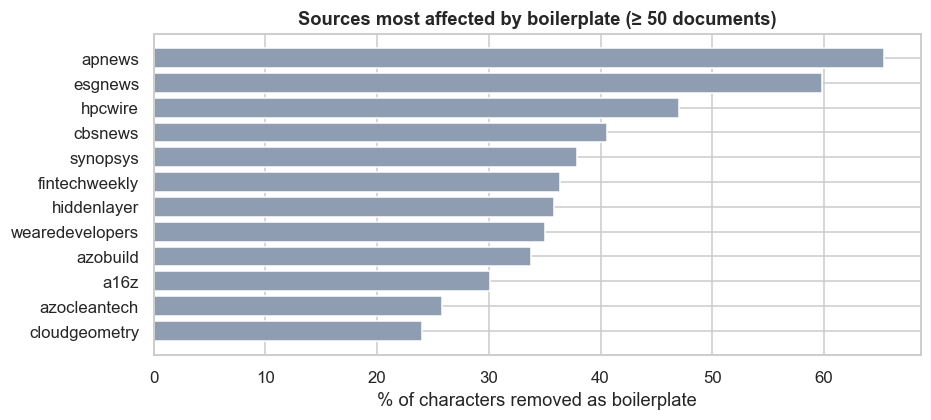

In [7]:
if not CLEAN_CACHED:
    t0 = time.time()
    dom_n = raw["domain"].value_counts()
    threshold = {d: max(BOILERPLATE_MIN_DOCS, math.ceil(BOILERPLATE_MIN_SHARE * n)) for d, n in dom_n.items()}
    para_df = Counter()
    for paras, d in zip(raw["paras"], raw["domain"]):
        for p in {x.strip() for x in paras if x.strip()}:
            para_df[(d, p)] += 1
    boiler = {key for key, n in para_df.items() if n >= threshold[key[0]]}
    kept, n_removed = [], []
    chars_before = chars_after = paras_before = 0
    dom_before, dom_removed = Counter(), Counter()
    for paras, d in zip(raw["paras"], raw["domain"]):
        keep = []
        for x in paras:
            s = x.strip()
            paras_before += 1; chars_before += len(x); dom_before[d] += len(x)
            if s and (d, s) not in boiler:
                keep.append(s); chars_after += len(s)
            else:
                dom_removed[d] += len(x)
        kept.append(keep); n_removed.append(len(paras) - len(keep))
    raw["paras"] = kept
    raw["n_paras_removed"] = n_removed
    raw["n_paras"] = [len(k) for k in kept]
    track_rx = re.compile(r"(?i)open[- ]?source|open[- ]?weight|\bopenai\b|\bllama\b|deepseek|mistral|hugging ?face")
    boiler_counts = sorted(((n, d, p) for (d, p), n in para_df.items() if (d, p) in boiler), reverse=True)
    LOG["boilerplate"] = {
        "rule": f"paragraph repeated in >= max({BOILERPLATE_MIN_DOCS}, {BOILERPLATE_MIN_SHARE:.0%} of the source's docs) docs of the same source",
        "boilerplate_paragraph_types": len(boiler),
        "paragraphs_removed": int(sum(n_removed)),
        "share_paragraphs_removed": sum(n_removed) / paras_before,
        "share_chars_removed": 1 - chars_after / chars_before,
        "docs_affected": int(sum(n > 0 for n in n_removed)),
        "top_examples": [[n, d, p[:150]] for n, d, p in boiler_counts[:10]],
        "track_term_examples": [[n, d, p[:150]] for n, d, p in boiler_counts if track_rx.search(p)][:8],
        "top_sources_by_removed_share": sorted(([d, round(dom_removed[d] / dom_before[d], 3), int(dom_n[d])]
                                                for d in dom_before if dom_n[d] >= 50), key=lambda r: -r[1])[:12],
        "seconds": round(time.time() - t0, 1),
    }
    del para_df, boiler, boiler_counts, kept
    gc.collect()

bp = LOG["boilerplate"]
print(f"Rule: {bp['rule']}")
print(f"Boilerplate paragraph types: {bp['boilerplate_paragraph_types']:,} | paragraphs removed: {bp['paragraphs_removed']:,} "
      f"({bp['share_paragraphs_removed']:.1%}, incl. empty ones) | characters removed: {bp['share_chars_removed']:.1%} "
      f"| documents affected: {bp['docs_affected']:,}")
display(pd.DataFrame(bp["top_examples"], columns=["documents", "source", "most frequent boilerplate paragraphs (truncated)"]))
print("Boilerplate paragraphs that would have produced false open-model signals:")
display(pd.DataFrame(bp["track_term_examples"], columns=["documents", "source", "paragraph (truncated)"]))
src_share = pd.DataFrame(bp["top_sources_by_removed_share"], columns=["source", "share_removed", "documents"])
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.barh(src_share["source"][::-1], src_share["share_removed"][::-1] * 100, color="#8f9db3")
ax.set_xlabel("% of characters removed as boilerplate"); ax.set_title("Sources most affected by boilerplate (≥ 50 documents)")
save_fig(fig, "01_boilerplate_by_source")

### 4.2 Text repair
The provider's text went through a tokenizer and back, which left artefacts in most documents: *Meta’ s*, *We’ re*, opening `` and closing '' quotes in the old Penn-Treebank style, and *( word*. Some documents also contain mojibake (*StÃ©phane*) and invisible zero-width characters. We repair these (Unicode **NFC**, `ftfy` only on documents flagged as garbled, quotes kept curly) because surface form matters for entity matching: *Meta’ s* would otherwise yield the token *s*. Case and punctuation are preserved.

In [8]:
MOJIBAKE_RX = re.compile(r"â€|Ã[\u0080-\u00bf]")
ZERO_WIDTH_RX = re.compile("[\u200b\u200c\u200d\u2060\ufeff]")
APOS_RX = re.compile(r"([’']) (s|re|ve|ll|m|d|t)\b")       # Meta’ s -> Meta’s
SPACE_APOS_RX = re.compile(r" '(s|re|ve|ll|m|d)\b")        # I 'm   -> I'm

def repair(text, stats):
    if MOJIBAKE_RX.search(text):
        text = ftfy.fix_text(text, uncurl_quotes=False, fix_latin_ligatures=False, fix_character_width=False)
        stats["documents_mojibake_fixed"] += 1
    text = unicodedata.normalize("NFC", text)
    text, n = ZERO_WIDTH_RX.subn("", text); stats["zero_width_chars_removed"] += n
    text, n1 = APOS_RX.subn(r"\1\2", text)
    text, n2 = SPACE_APOS_RX.subn(r"'\1", text); stats["apostrophe_spacing_fixed"] += n1 + n2
    n = text.count("``") + text.count("''")
    if n:
        stats["ptb_quotes_fixed"] += n
        text = text.replace("`` ", '"').replace("``", '"').replace(" ''", '"').replace("''", '"')
    n = text.count("( ")
    if n:
        stats["parenthesis_spacing_fixed"] += n
        text = text.replace("( ", "(")
    return text

if not CLEAN_CACHED:
    t0 = time.time()
    examples = []
    for rx in [APOS_RX, re.compile(r"``"), MOJIBAKE_RX]:
        for paras in raw["paras"]:
            s = "\n\n".join(paras)
            m = rx.search(s)
            if m:
                window = s[max(0, m.start() - 55): m.end() + 55].replace("\n", " ")
                examples.append([window, repair(window, Counter())])
                break
    rstats = Counter()
    raw["text"] = [repair("\n\n".join(p), rstats) for p in raw["paras"]]
    raw["title"] = [repair(t, Counter()) for t in raw["title"]]
    raw = raw.drop(columns=["paras"])
    gc.collect()
    raw["n_chars"] = raw["text"].str.len()
    LOG["repair"] = {**{k: int(v) for k, v in rstats.items()}, "examples": examples, "seconds": round(time.time() - t0, 1)}

print({k: v for k, v in LOG["repair"].items() if k not in ("examples", "seconds")})
display(pd.DataFrame(LOG["repair"]["examples"], columns=["before", "after"]))

{'zero_width_chars_removed': 32507, 'apostrophe_spacing_fixed': 681159, 'parenthesis_spacing_fixed': 269632, 'ptb_quotes_fixed': 160588, 'documents_mojibake_fixed': 167}


,before,after
0,nt systems and energy management solutions. The company’ s AI-driven technologies facilitate real-time dat...,nt systems and energy management solutions. The company’s AI-driven technologies facilitate real-time data...
1,"w.azobuild.com/news.aspx? newsID=23603. Dhull, Nidhi. `` Optimizing Sustainable Construction with Smart T...","w.azobuild.com/news.aspx? newsID=23603. Dhull, Nidhi. ""Optimizing Sustainable Construction with Smart Too..."
2,"ri Libarikian, Kayvaun Rowshankish, Markus Berger-de LeÃ³n, and Vishnu Kamalnath, âFrom raw data to real...","ri Libarikian, Kayvaun Rowshankish, Markus Berger-de León, and Vishnu Kamalnath, “From raw data to real profi"


### 4.3 Minimum content after cleaning
Once their "related stories" teasers are removed, some pages are nearly empty, for example AP video pages that hold a single caption. They entered an AI corpus only through the AI headlines in their teasers. We keep documents with at least 1,500 characters of remaining text.

In [9]:
if not CLEAN_CACHED:
    short = raw["n_chars"] < MIN_CHARS
    example = raw.loc[short & raw["domain"].eq("apnews")].head(1)
    LOG["min_content"] = {
        "removed": int(short.sum()),
        "removed_by_source": {k: int(v) for k, v in raw.loc[short, "domain"].value_counts().head(8).items()},
        "example": None if example.empty else {"title": example["title"].iloc[0], "remaining_text": example["text"].iloc[0][:300]},
    }
    raw = raw.loc[~short]
    LOG["funnel"].append(["≥ 1,500 characters after boilerplate removal", len(raw)])
mc = LOG["min_content"]
print(f"Removed {mc['removed']:,} near-empty documents. By source: {mc['removed_by_source']}")
if mc["example"]:
    print("Example:", mc["example"]["title"], "→ remaining text:", repr(mc["example"]["remaining_text"][:220]))

Removed 992 near-empty documents. By source: {'apnews': 578, 'synopsys': 157, 'builtin': 89, 'cbsnews': 42, 'a16z': 41, 'wearedevelopers': 31, 'hiddenlayer': 20, 'huggingface': 9}
Example: Highlights of Grand Slam champion Rafael Nadal's career in photos → remaining text: 'Rafael Nadal is retiring from professional tennis at age 38 after winning 22 Grand Slam titles during an unprecedented era he shared with rivals Roger Federer and Novak Djokovic.'


### 4.4 Language
A share of English stop words is computed for every document, which is fast and transparent. Only documents with a low share (< 0.25) are passed to `langdetect` for confirmation.

In [10]:
EN_STOP = set("the of and to in a is that for on with as by it this are be from at an or was have has will its their not but which "
              "more can they we also than been about new into other these said says".split())
ALPHA_RX = re.compile(r"[A-Za-z]+")

def en_stopword_ratio(text):
    words = ALPHA_RX.findall(text[:3000].lower())[:400]
    return sum(w in EN_STOP for w in words) / max(len(words), 1)

def safe_detect(text):
    try:
        return detect(text)
    except Exception:
        return "unknown"

if not CLEAN_CACHED:
    t0 = time.time()
    raw["en_sw_ratio"] = raw["text"].map(en_stopword_ratio)
    candidates = raw.index[raw["en_sw_ratio"] < EN_STOPWORD_RATIO_MIN]
    raw["lang"] = "en"
    raw.loc[candidates, "lang"] = [safe_detect(raw.at[i, "text"][:2000]) for i in candidates]
    non_en = raw["lang"].ne("en")
    LOG["language"] = {
        "checked_with_langdetect": int(len(candidates)), "removed": int(non_en.sum()),
        "removed_by_language": {k: int(v) for k, v in raw.loc[non_en, "lang"].value_counts().items()},
        "removed_by_source": {k: int(v) for k, v in raw.loc[non_en, "domain"].value_counts().head(6).items()},
        "seconds": round(time.time() - t0, 1),
    }
    raw = raw.loc[~non_en]
    LOG["funnel"].append(["English", len(raw)])
lg = LOG["language"]
print(f"Checked with langdetect: {lg['checked_with_langdetect']:,} | removed as non-English: {lg['removed']:,}")
print("By language:", lg["removed_by_language"]); print("By source:", lg["removed_by_source"])

Checked with langdetect: 2,887 | removed as non-English: 357
By language: {'es': 135, 'de': 105, 'pt': 47, 'fr': 32, 'id': 8, 'ko': 8, 'nl': 8, 'it': 6, 'no': 2, 'pl': 2, 'ro': 2, 'cs': 1, 'sk': 1}
By source: {'blog.google': 139, 'gitnation': 56, 't3': 39, 'alexanderthamm': 19, 'workday': 19, 'meer': 8}


### 4.5 Exact and near-duplicates
Syndication and re-crawls multiply the same story, so duplicates would inflate any trend. The procedure:
* **Exact duplicates** share the same fingerprint of their lower-cased alphanumeric text.
* **Near-duplicates** are found with MinHash on 5-word shingles (64 permutations, LSH with 8 bands × 8 rows) and confirmed when the estimated Jaccard similarity is ≥ 0.8.
* Duplicates are merged with union-find, and the **earliest** document of each cluster is kept. Its `dup_cluster_size` records how many copies existed, which measures how widely a story was syndicated.

In [11]:
ALNUM_RX = re.compile(r"[a-z0-9]+")
_P = np.uint64(4_294_967_311)                          # prime > 2^32, products stay below 2^64
_rng = np.random.default_rng(SEED)
_A = _rng.integers(1, 2**32 - 1, MINHASH_PERM, dtype=np.uint64)
_B = _rng.integers(0, 2**32 - 1, MINHASH_PERM, dtype=np.uint64)

def minhash_signature(text):
    words = ALNUM_RX.findall(text.lower())[:SHINGLE_MAX_WORDS]
    shingles = {zlib.crc32(" ".join(words[i:i + SHINGLE_K]).encode()) for i in range(max(len(words) - SHINGLE_K + 1, 1))}
    x = np.fromiter(shingles, dtype=np.uint64, count=len(shingles))
    return ((np.outer(x, _A) + _B) % _P).min(axis=0)

if not CLEAN_CACHED:
    t0 = time.time()
    raw = raw.sort_values(["date", "src_row"]).reset_index(drop=True)   # earliest copy first
    fingerprints = [hashlib.sha1(" ".join(ALNUM_RX.findall(t.lower())).encode()).hexdigest() for t in raw["text"]]
    exact_dup = pd.Series(fingerprints).duplicated(keep="first").to_numpy()
    sigs = np.vstack([minhash_signature(t) for t in raw["text"]])
    rows_per_band = MINHASH_PERM // MINHASH_BANDS
    buckets = defaultdict(list)
    for b in range(MINHASH_BANDS):
        for i, row in enumerate(sigs[:, b * rows_per_band:(b + 1) * rows_per_band]):
            buckets[(b, row.tobytes())].append(i)
    parent = np.arange(len(raw))

    def find(i):
        while parent[i] != i:
            parent[i] = parent[parent[i]]
            i = parent[i]
        return i

    def union(a, c):
        ra, rc = find(a), find(c)
        if ra != rc:
            parent[max(ra, rc)] = min(ra, rc)   # the earlier document becomes the cluster root

    checked, n_pairs = set(), 0
    for members in buckets.values():
        if 1 < len(members) <= 200:
            for x_i in range(len(members)):
                for y_i in range(x_i + 1, len(members)):
                    pair = (members[x_i], members[y_i])
                    if pair not in checked:
                        checked.add(pair)
                        if (sigs[pair[0]] == sigs[pair[1]]).mean() >= NEAR_DUP_THRESHOLD:
                            n_pairs += 1
                            union(*pair)
    first_of = {}
    for i, h in enumerate(fingerprints):
        if h in first_of:
            union(first_of[h], i)
        else:
            first_of[h] = i
    root = np.array([find(i) for i in range(len(raw))])
    is_dup = root != np.arange(len(raw))
    raw["dup_cluster_size"] = pd.Series(root).map(pd.Series(root).value_counts()).to_numpy()
    clusters = pd.DataFrame({"root": root, "source": raw["domain"].to_numpy(), "title": raw["title"].to_numpy(), "date": raw["date"].to_numpy()})
    clusters = clusters[clusters.duplicated("root", keep=False)]
    summary = clusters.groupby("root").agg(copies=("source", "size"), n_sources=("source", "nunique"),
                                           first=("date", "min"), last=("date", "max"), title=("title", "first"))
    summary["sources"] = clusters.groupby("root")["source"].agg(lambda s: ", ".join(sorted(set(s)))[:70])
    summary["first"], summary["last"] = summary["first"].dt.date.astype(str), summary["last"].dt.date.astype(str)
    cols = ["copies", "n_sources", "first", "last", "title", "sources"]
    LOG["dedup"] = {
        "exact_duplicates": int(exact_dup.sum()), "near_duplicate_pairs_confirmed": n_pairs,
        "docs_removed": int(is_dup.sum()), "clusters": int(len(summary)), "cross_source_clusters": int((summary["n_sources"] > 1).sum()),
        "largest_clusters": summary.sort_values("copies", ascending=False)[cols].head(6).values.tolist(),
        "cross_source_examples": summary[summary["n_sources"] > 1].sort_values("copies", ascending=False)[cols].head(6).values.tolist(),
        "seconds": round(time.time() - t0, 1),
    }
    raw = raw.loc[~is_dup]
    LOG["funnel"].append(["Exact and near-duplicates removed", len(raw)])
    del sigs, buckets, checked, fingerprints
    gc.collect()

dd = LOG["dedup"]
print(f"Exact duplicates: {dd['exact_duplicates']} | confirmed near-duplicate pairs: {dd['near_duplicate_pairs_confirmed']} | "
      f"documents removed: {dd['docs_removed']} | clusters: {dd['clusters']} (of which {dd['cross_source_clusters']} span several sources)")
print("Largest clusters:")
display(pd.DataFrame(dd["largest_clusters"], columns=["copies", "sources_n", "first", "last", "title", "sources"]))
print("Cross-source clusters (syndication):")
display(pd.DataFrame(dd["cross_source_examples"], columns=["copies", "sources_n", "first", "last", "title", "sources"]))

Exact duplicates: 119 | confirmed near-duplicate pairs: 613 | documents removed: 529 | clusters: 472 (of which 100 span several sources)
Largest clusters:


,copies,sources_n,first,last,title,sources
0,8,1,2026-01-13,2026-02-10,"Territory Account Manager, NE - Carbon Robotics",builtin
1,7,1,2024-09-18,2025-04-23,meta-llama/Llama-3.2-3B-Instruct · Hugging Face,huggingface
2,6,1,2025-12-06,2025-12-25,"Software Engineer II, Full Stack (Human AI Innovation Team) - Dataminr",builtin
3,5,1,2026-01-10,2026-02-08,"Strategic Account Executive, Indiana/Ohio - Rubrik",builtin
4,4,1,2024-09-25,2024-09-25,QuantFactory/Llama-3.2-3B-GGUF · Hugging Face,huggingface
5,4,1,2026-06-28,2026-06-28,HR Workshop - Vibe: athon: Where HR Goes to Build 4/4 Â· WeAreDevelopers World Congress,wearedevelopers


Cross-source clusters (syndication):


,copies,sources_n,first,last,title,sources
0,3,2,2024-11-28,2024-12-01,GitHub - Tencent/HunyuanVideo: HunyuanVideo: A Systematic Framework For Large Video Generation Model,"deeplearning, huggingface"
1,3,3,2026-04-22,2026-04-22,A robot Sony built with AI is defeating human pros at table tennis,"apnews, bnnbloomberg, thestar"
2,3,2,2025-07-30,2025-08-14,google/gemma-3-270m-it · Hugging Face,"ai.google, huggingface"
3,3,3,2025-07-23,2025-07-23,"Teens say they are turning to AI for advice, friendship and more","apnews, bnnbloomberg, thestar"
4,2,2,2024-10-09,2024-10-10,Australia’s TPG Telecom Taps Mavenir to Boost Voice Security For Mobile Users and Block AI-Driven Scam Calls,"macaubusiness, thefastmode"
5,2,2,2024-10-09,2024-10-11,Machine learning cracked the protein-folding problem and won the 2024 Nobel Prize in chemistry,"discovermagazine, theconversation"


### 4.6 Study window and cleaned corpus

Window: {'removed_outside_window': 229, 'first_date': '2024-09-11', 'last_date': '2026-08-31'} 
Clean corpus: 45,644 documents | 68.7 M words | 391 sources | 2024-09-11 → 2026-08-31


,step,documents,removed
0,Raw dataset,47751,0
1,"≥ 1,500 characters after boilerplate removal",46759,992
2,English,46402,357
3,Exact and near-duplicates removed,45873,529
4,Study window Sep 2024 – Aug 2026,45644,229


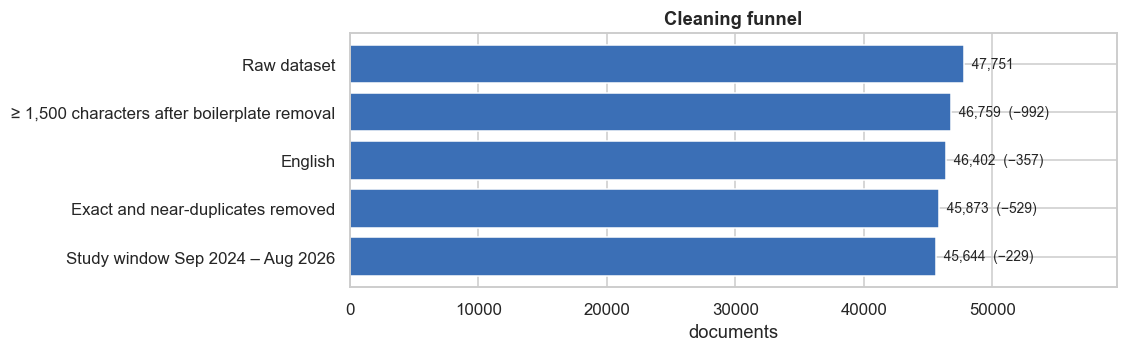

In [12]:
if not CLEAN_CACHED:
    in_window = raw["date"].between(STUDY_START, STUDY_END)
    LOG["window"] = {"removed_outside_window": int((~in_window).sum()),
                     "first_date": str(raw.loc[in_window, "date"].min().date()), "last_date": str(raw.loc[in_window, "date"].max().date())}
    df = raw.loc[in_window].reset_index(drop=True)
    LOG["funnel"].append(["Study window Sep 2024 – Aug 2026", len(df)])
    del raw
    gc.collect()
    df["n_words"] = [len(t.split()) for t in df["text"]]
    df["month"] = df["date"].dt.to_period("M").astype(str)
    df["quarter"] = df["date"].dt.to_period("Q").astype(str)
    CLEAN_COLS = ["doc_id", "src_row", "date", "month", "quarter", "domain", "url", "title", "text", "tags",
                  "n_paras", "n_paras_removed", "n_chars", "n_words", "en_sw_ratio", "dup_cluster_size"]
    df = df[CLEAN_COLS]
    df.to_parquet(CLEAN_PATH, index=False)
    LOG_PATH.write_text(json.dumps(LOG, indent=2, ensure_ascii=False, default=str), encoding="utf-8")
else:
    del raw
    gc.collect()
    df = pd.read_parquet(CLEAN_PATH)
    df = df[["doc_id", "src_row", "date", "month", "quarter", "domain", "url", "title", "text", "tags",
             "n_paras", "n_paras_removed", "n_chars", "n_words", "en_sw_ratio", "dup_cluster_size"]]

print(f"Window: {LOG['window']} ")
print(f"Clean corpus: {len(df):,} documents | {df['n_words'].sum() / 1e6:.1f} M words | {df['domain'].nunique()} sources | "
      f"{df['date'].min().date()} → {df['date'].max().date()}")
funnel = pd.DataFrame(LOG["funnel"], columns=["step", "documents"])
funnel["removed"] = (-funnel["documents"].diff()).fillna(0).astype(int)
display(funnel)
fig, ax = plt.subplots(figsize=(9, 3))
ax.barh(funnel["step"][::-1], funnel["documents"][::-1], color="#3b6fb6")
for y, (n, r) in enumerate(zip(funnel["documents"][::-1], funnel["removed"][::-1])):
    ax.text(n, y, f"  {n:,}" + (f"  (−{r:,})" if r else ""), va="center", fontsize=9)
ax.set_xlim(0, funnel["documents"].max() * 1.25); ax.set_xlabel("documents"); ax.set_title("Cleaning funnel")
save_fig(fig, "02_cleaning_funnel")

**What cleaning changed.** This reference run loaded the cleaned corpus from `data/processed/`. All numbers above come from the transform log written when the corpus was built.
* **Funnel:** 47,751 → 45,644 documents (−4.4 %).
* **Boilerplate:** the source-level rule removed 15.9 % of paragraphs but only 9.8 % of characters, because templates are short. It matters directly for this track:
  * a DEV footer containing *the open source software that powers DEV* appears in 1,131 documents;
  * a chatbot disclaimer that mentions OpenAI appears in 603 documents.
  Both would otherwise create false openness and model signals.
* **Repair:** about 681,000 apostrophe artefacts (*Meta’ s*), 161,000 Penn-Treebank quotes and 270,000 parenthesis artefacts were fixed, and 167 garbled documents were repaired.
* **Filters:**
  * 992 near-empty pages, mostly AP video pages whose only AI content was a teaser;
  * 357 non-English documents, mostly localised Google blog posts;
  * 529 duplicates in 472 clusters, of which 100 span several sources (syndication). The rest are re-crawled Hugging Face model cards (the Llama-3.2-3B-Instruct card appears 7 times) and job ads;
  * 229 documents from September 2026, outside the study window.

## 5. Corpus diagnostics
Diagnostic plots test the data-generating pipeline before they describe the world. Three questions matter for trend analysis:
* Does collection volume vary over time? If it does, raw counts would imitate trends.
* Is the corpus dominated by a few sources?
* Are document lengths plausible?

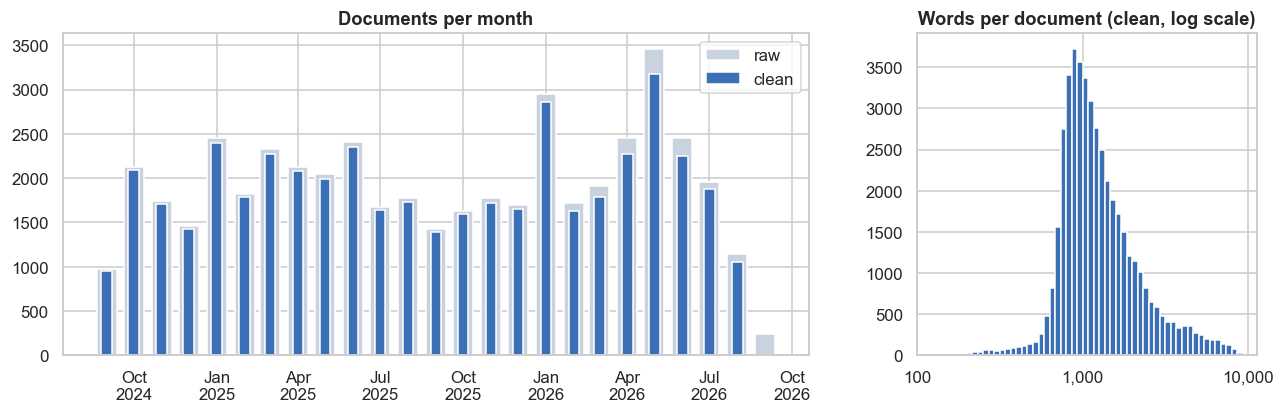

Monthly volume (clean): min 953 (2024-09), max 3,176 (2026-05), ratio max/min 3.3. September 2024 starts on 2024-09-11 (partial month).
Words per document: median 1,134, 1st percentile 383, 99th percentile 6,577


In [13]:
raw_m = pd.Series(LOG["raw_monthly"]).sort_index()
clean_m = df["month"].value_counts().sort_index()
vol = pd.DataFrame({"raw": raw_m, "clean": clean_m}).fillna(0)
vol.index = pd.to_datetime(vol.index + "-01")
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), gridspec_kw={"width_ratios": [2.2, 1]})
axes[0].bar(vol.index, vol["raw"], width=22, color="#c9d3df", label="raw")
axes[0].bar(vol.index, vol["clean"], width=12, color="#3b6fb6", label="clean")
axes[0].set_title("Documents per month"); axes[0].legend(); axes[0].xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
axes[1].hist(np.log10(df["n_words"].clip(lower=10)), bins=50, color="#3b6fb6")
axes[1].set_xticks([2, 3, 4]); axes[1].set_xticklabels(["100", "1,000", "10,000"])
axes[1].set_title("Words per document (clean, log scale)")
save_fig(fig, "03_volume_and_length")
print(f"Monthly volume (clean): min {clean_m.min():,} ({clean_m.idxmin()}), max {clean_m.max():,} ({clean_m.idxmax()}), "
      f"ratio max/min {clean_m.max() / clean_m.min():.1f}. September 2024 starts on {df['date'].min().date()} (partial month).")
print(f"Words per document: median {df['n_words'].median():,.0f}, 1st percentile {df['n_words'].quantile(.01):,.0f}, 99th percentile {df['n_words'].quantile(.99):,.0f}")

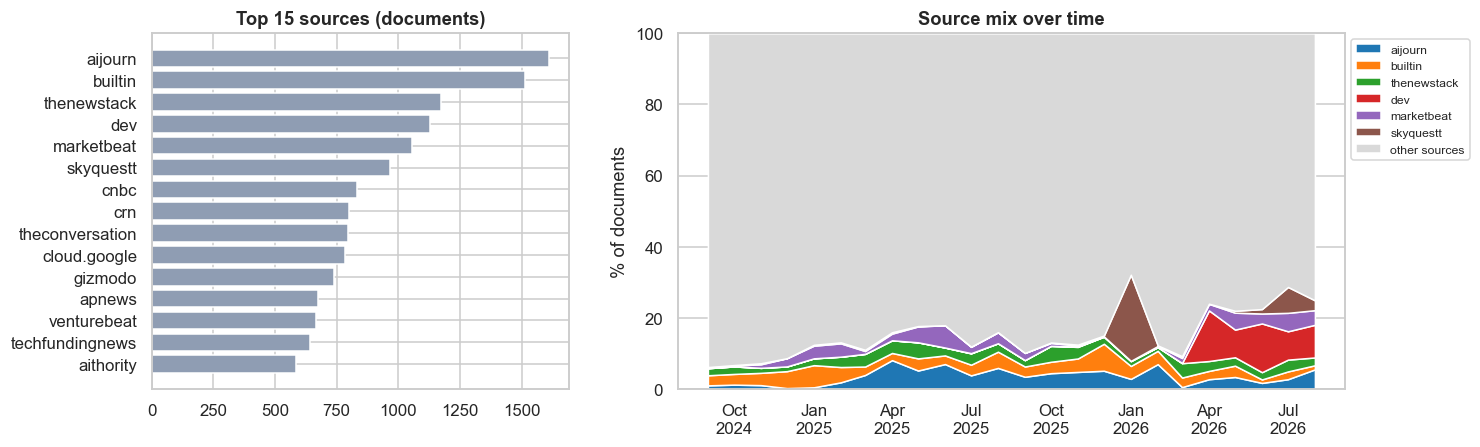

391 sources; the top 10 provide 23.4% of documents; 120 sources have ≥ 100 documents.


In [14]:
src = df["domain"].value_counts()
top6 = src.index[:6]
src_month = pd.crosstab(df["month"], df["domain"].where(df["domain"].isin(top6), "other sources"), normalize="index")
src_month = src_month[list(top6) + ["other sources"]]
src_month.index = pd.to_datetime(src_month.index + "-01")
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={"width_ratios": [1, 1.6]})
axes[0].barh(src.index[:15][::-1], src.values[:15][::-1], color="#8f9db3"); axes[0].set_title("Top 15 sources (documents)")
axes[1].stackplot(src_month.index, (src_month.T * 100).values, labels=src_month.columns,
                  colors=sns.color_palette("tab10", 6) + [(0.85, 0.85, 0.85)])
axes[1].set_ylim(0, 100); axes[1].set_ylabel("% of documents"); axes[1].set_title("Source mix over time")
axes[1].legend(loc="upper left", bbox_to_anchor=(1, 1), fontsize=8); axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
save_fig(fig, "04_sources")
print(f"{df['domain'].nunique()} sources; the top 10 provide {src.iloc[:10].sum() / len(df):.1%} of documents; "
      f"{(src >= 100).sum()} sources have ≥ 100 documents.")

**Corpus shape.**
* **Volume:** monthly volume varies by a factor of 3.3, from 953 documents (September 2024, partial) to 3,176 (May 2026). Raw counts would therefore manufacture trends, so every trend below is a share of the month's documents.
* **Length:** median 1,134 words, and 99 % of documents are under 6,600 words.
* **Sources:** the corpus is spread over 391 sources; the top 10 provide only 23 %.

## 6. Text representations
One article serves several purposes, so we keep separate **views** derived from the same immutable source.

| View | Content | Used for |
|---|---|---|
| **Fidelity text** (`text` column) | repaired, NFC, case and punctuation kept, paragraphs separated by blank lines | NER and relation extraction (WP2), quotations, RAG passages (Stage 3) |
| **Matching view** (computed on the fly) | fidelity text with hyphen variants (U+2010–2013, U+2212), curly quotes, ellipsis and ligatures mapped to ASCII | lexicon matching: *open‑weight* written with a non-breaking hyphen still matches |
| **Analysis view** (Section 9, track subset only) | lemmas, lower-cased, stop words removed, multi-word expressions and model names normalised | topic modelling |

Character offsets of the fidelity text remain the common coordinate system. The matching view maps characters one-to-one, except the ellipsis and the fi/fl ligatures, which expand to several characters. Offsets found in it therefore match the source, except after those characters, where they must be re-aligned.

In [15]:
MATCH_MAP = str.maketrans({"\u2010": "-", "\u2011": "-", "\u2012": "-", "\u2013": "-", "\u2212": "-", "\u2018": "'", "\u2019": "'",
                           "\u201c": '"', "\u201d": '"', "\u2026": "...", "\u00a0": " ", "\ufb01": "fi", "\ufb02": "fl"})

def match_view(s):
    return s.translate(MATCH_MAP)

print(match_view("OpenAI’s gpt‑oss is an “open‑weight” model…"))

OpenAI's gpt-oss is an "open-weight" model...


## 7. Open-models track: lexicon, matching and relevance tiers
### 7.1 A gazetteer of open-model families
The dataset's `tags` cover many model families, but there is **no tag for openness itself** ("open source", "open weight"), and tags cannot say *how central* a model is to an article. We therefore build a transparent lexicon with three parts:
* **35 model families**, each with developer, developer region and modality, fast literal triggers and a precise regular expression;
* **openness concepts**: *open-weight*, *open-source model*, *open models*, *released the weights*, the OSI definition / *open-washing*, and the weaker *open-source AI*;
* **ecosystem terms**: Hugging Face, Ollama, llama.cpp, vLLM, GGUF, LM Studio, LoRA.

The patterns encode the ambiguity cases discussed in Courses 1 and 3:

| Risk | Example | Rule |
|---|---|---|
| Not an open model | *OpenAI*, *OpenClaw*, *LlamaIndex*, *Ollama* | word boundaries; *open* must modify a model noun |
| Other referents | *Falcon 9* (SpaceX), *CrowdStrike Falcon* | Falcon only with LLM versions (*Falcon 3*, *Falcon-H1*, *Falcon-180B*) |
| Person names | *Gemma Sharp*, *Kimi Räikkönen* | exclude a following surname or known names |
| Common words | *Phi*, *Granite*, *GLM* (statistics), *BLOOM* | require a version (*Phi-4*, *Granite 3.0*, *GLM-4.5*) or upper case |
| Case | *LoRA* (fine-tuning) vs *LoRa* (radio) | case-sensitive patterns |
| Generic "open source" | *open-source framework*, *open source development model* | the noun after *open source* must be a model noun |
| Typography | *open‑weight* with a non-breaking hyphen | matching view (Section 6) |

The lexicon is exported to `artifacts/stage1_wp1/lexicon/open_models_lexicon.json`. WP2 can reuse it as a gazetteer, with the family id as the canonical identity (Course 3: normalisation separates how an entity is written from how it is stored).

In [16]:
FAMILIES = {
    # ---------------- United States ----------------
    "llama": dict(label="Llama", developer="Meta", region="US", modality="text/multimodal", kw=["Llama", "LLaMA", "LLAMA"],
                  rx=r"\b(?:Llama|LLaMA|LLAMA)(?:Con)?\b", tags=["Llama", "Llama2", "Llama3", "Llama4", "CodeLlama", "TinyLlama"]),
    "gemma": dict(label="Gemma", developer="Google", region="US", modality="text/multimodal", kw=["Gemma"],
                  rx=r"\b(?:Code|Med|Pali|Shield|Embedding|Function|Vault|T5|Data|Diffusion|Recurrent|Sign|Dolphin|Tx)?Gemma\b"
                     r"(?!\s(?!(?:Scope|Team|Models?|Family|Nano|Open|Developer|Day|Good|Robotics|Vision)\b)[A-Z][a-z]+)",
                  tags=["Gemma", "EmbeddingGemma", "DiffusionGemma"]),
    "phi": dict(label="Phi", developer="Microsoft", region="US", modality="text/multimodal", kw=["Phi-", "Phi "],
                rx=r"\bPhi[- ]?(?:[1-4](?:\.5)?|Silica)\b", tags=["Phi2", "Phi3", "Phi4"]),
    "nemotron": dict(label="Nemotron", developer="NVIDIA", region="US", modality="text", kw=["Nemotron"], rx=r"\bNemotron\b",
                     tags=["Nemotron", "LlamaNemotron"]),
    "gpt_oss": dict(label="gpt-oss", developer="OpenAI", region="US", modality="text",
                    kw=["gpt-oss", "GPT-OSS", "gpt oss", "GPT-oss", "Gpt-oss", "GPT OSS"], rx=r"(?i)\bgpt[- ]oss\b", tags=["GPTOSS"]),
    "granite": dict(label="Granite", developer="IBM", region="US", modality="text", kw=["Granite"],
                    rx=r"\bGranite[- ]?\d(?:\.\d)?\b|\bIBM(?:'s)?\s+Granite\b|\bGranite\s+(?:models?|family|LLMs?|Guardian|Vision|Code|Embedding)\b",
                    tags=["IBMGranite"]),
    "olmo": dict(label="OLMo / Molmo / Tülu", developer="Ai2", region="US", modality="text/multimodal",
                 kw=["OLMo", "Olmo", "Molmo", "Tülu", "Tulu"], rx=r"\b(?:OLMo|Olmo|Molmo)\b|\bT[üu]lu[- ]?\d\b", tags=["Olmo"]),
    "dbrx": dict(label="DBRX", developer="Databricks", region="US", modality="text", kw=["DBRX"], rx=r"\bDBRX\b", tags=[]),
    "arctic": dict(label="Snowflake Arctic", developer="Snowflake", region="US", modality="text", kw=["Arctic"],
                   rx=r"\bSnowflake(?:'s)?\s+Arctic\b|\bArctic[- ](?:Embed|LLM|Instruct)\b", tags=[]),
    "starcoder": dict(label="StarCoder", developer="BigCode", region="US", modality="code", kw=["StarCoder"], rx=r"\bStarCoder\d?\b",
                      tags=["StarCoder"]),
    "smollm": dict(label="SmolLM", developer="Hugging Face", region="US", modality="text/multimodal", kw=["SmolLM", "SmolVLM"],
                   rx=r"\bSmol(?:LM|VLM)\d?\b", tags=["SmolLM"]),
    "eleuther": dict(label="Pythia / GPT-NeoX", developer="EleutherAI", region="US", modality="text", kw=["Pythia", "GPT-Neo", "GPT-J"],
                     rx=r"\bPythia\b|\bGPT-Neo(?:X)?\b|\bGPT-J\b", tags=["Pythia"]),
    "hermes": dict(label="Hermes", developer="Nous Research", region="US", modality="text", kw=["Hermes"],
                   rx=r"\bHermes[- ]?[2-4]\b|\bNous Hermes\b", tags=[]),
    "grok_open": dict(label="Grok (open releases)", developer="xAI", region="US", modality="text", kw=["Grok"],
                      rx=r"\bGrok[- ]?(?:1|2\.5)\b", tags=[]),
    # ---------------- Europe ----------------
    "mistral": dict(label="Mistral", developer="Mistral AI", region="Europe", modality="text/multimodal",
                    kw=["Mistral", "Mixtral", "Ministral", "Codestral", "Pixtral", "Magistral", "Devstral", "Voxtral", "Mathstral"],
                    rx=r"\b(?:Mistral|Mixtral|Ministral|Codestral|Pixtral|Magistral|Devstral|Voxtral|Mathstral)\b", tags=["Mistral", "Mixtral"]),
    "apertus": dict(label="Apertus", developer="Swiss AI Initiative", region="Europe", modality="text", kw=["Apertus"],
                    rx=r"\bApertus\b", tags=["Apertus"]),
    "eurollm": dict(label="EuroLLM / Teuken", developer="EU research consortia", region="Europe", modality="text",
                    kw=["EuroLLM", "Teuken"], rx=r"\b(?:Open)?EuroLLM\b|\bTeuken\b", tags=[]),
    "bloom": dict(label="BLOOM", developer="BigScience", region="Europe", modality="text", kw=["BLOOM"], rx=r"\bBLOOMZ?\b", tags=["BLOOM"]),
    "flux": dict(label="FLUX", developer="Black Forest Labs", region="Europe", modality="image", kw=["FLUX", "Flux.", "Black Forest Labs"],
                 rx=r"\bFLUX(?:\.\d)?\b|\bFlux\.\d\b|\bBlack Forest Labs\b", tags=[]),
    "stable_diffusion": dict(label="Stable Diffusion / StableLM", developer="Stability AI", region="Europe", modality="image",
                             kw=["Stable Diffusion", "StableLM", "Stable LM", "SDXL", "Stable Audio", "Stable Video", "Stable Cascade"],
                             rx=r"\bStable\s?(?:Diffusion|LM|Audio|Video(?:\s+Diffusion)?|Cascade)\b|\bSDXL\b",
                             tags=["StableDiffusion", "StableLM"]),
    # ---------------- China ----------------
    "deepseek": dict(label="DeepSeek", developer="DeepSeek", region="China", modality="text", kw=["DeepSeek", "Deepseek", "DEEPSEEK"],
                     rx=r"\b(?:DeepSeek|Deepseek|DEEPSEEK)\b", tags=["DeepSeek"]),
    "qwen": dict(label="Qwen", developer="Alibaba", region="China", modality="text/multimodal", kw=["Qwen", "QwQ", "Tongyi"],
                 rx=r"\bQwen\w*|\bQwQ\b|\bTongyi\b", tags=["Qwen2", "Qwen3"]),
    "wan": dict(label="Wan", developer="Alibaba", region="China", modality="video", kw=["Wan2", "Wan 2", "Wan-2"],
                rx=r"\bWan[- ]?2\.\d\b", tags=[]),
    "kimi": dict(label="Kimi", developer="Moonshot AI", region="China", modality="text", kw=["Kimi", "Moonshot AI"],
                 rx=r"\bKimi\b(?!\s+(?:R[äa]ikk[öo]nen|Antonelli))|\bMoonshot AI\b", tags=["Kimi", "MoonshotAI"]),
    "glm": dict(label="GLM", developer="Zhipu AI (Z.ai)", region="China", modality="text", kw=["GLM", "Zhipu", "Z.ai"],
                rx=r"\b(?:Chat)?GLM[- ]?\d(?:\.\d)?\w*|\bZhipu\b|\bZ\.ai\b", tags=["GLM"]),
    "minimax": dict(label="MiniMax", developer="MiniMax", region="China", modality="text/multimodal", kw=["MiniMax"], rx=r"\bMiniMax\b",
                    tags=["MiniMax"]),
    "hunyuan": dict(label="Hunyuan", developer="Tencent", region="China", modality="text/multimodal", kw=["Hunyuan"], rx=r"\bHunyuan\w*",
                    tags=[]),
    "yi": dict(label="Yi", developer="01.AI", region="China", modality="text", kw=["01.AI", "Yi-"],
               rx=r"\b01\.AI\b|\bYi-(?:Lightning|Large|Coder|\d+B)\b", tags=[]),
    "baichuan": dict(label="Baichuan", developer="Baichuan", region="China", modality="text", kw=["Baichuan"], rx=r"\bBaichuan\b", tags=[]),
    "internlm": dict(label="InternLM / InternVL", developer="Shanghai AI Lab", region="China", modality="text/multimodal",
                     kw=["InternLM", "InternVL"], rx=r"\bIntern(?:LM|VL)\d?\b", tags=[]),
    # ---------------- other regions ----------------
    "falcon": dict(label="Falcon", developer="TII", region="Other", modality="text", kw=["Falcon"],
                   rx=r"\bFalcon[- ](?:\d+B|[23](?:\.\d)?|H1\w*|Mamba|Arabic|E|LLM|Edge)\b|\bFalconLLM\b|\bTII(?:'s)?\s+Falcon\b",
                   tags=["FalconLLM"]),
    "jais": dict(label="Jais", developer="G42 / Inception", region="Other", modality="text", kw=["Jais"], rx=r"\bJais\b", tags=[]),
    "jamba": dict(label="Jamba", developer="AI21 Labs", region="Other", modality="text", kw=["Jamba"], rx=r"\bJamba\b", tags=["Jamba"]),
    "cohere_open": dict(label="Command R / Aya", developer="Cohere", region="Other", modality="text",
                        kw=["Command R", "Command-R", "Command A", "Command-A", "Aya "],
                        rx=r"\bCommand[- ][RA]\+?\b|\bAya\s+(?:Expanse|Vision|23|101)\b", tags=[]),
    "sarvam": dict(label="Sarvam", developer="Sarvam AI", region="Other", modality="text", kw=["Sarvam"], rx=r"\bSarvam\b", tags=[]),
}
NOT_MODEL_NOUN = (r"(?:framework|frameworks|library|libraries|tool|tools|toolkit|platform|platforms|software|project|projects|community|"
                  r"communities|code|codebase|stack|ecosystem|repository|repositories|repo|database|protocol|protocols|standard|standards|"
                  r"agent|agents|implementation|alternative|alternatives|version|release|movement|initiative|developers?|development|"
                  r"business|licensing|license|governance|operating|pricing|delivery|funding|revenue|distribution|collaboration|security|"
                  r"support|subscription|services?|consumption|engagement|data|programming|partnership|maturity|innovation)")
CONCEPTS = {
    "open_weight": dict(kw=["open-weight", "open weight", "openweight"], rx=r"(?i)\bopen[- ]?weights?\b"),
    "open_source_model": dict(kw=["open-source", "open source", "opensource", "open-sourced"],
                              rx=r"(?i)\bopen[- ]?sourced?\s+(?:(?!" + NOT_MODEL_NOUN + r"\b)[\w.+-]+\s+){0,3}?"
                                 r"(?:language\s+models?|foundation\s+models?|models?|llms?|slms?|weights|checkpoints?)\b"),
    "open_model": dict(kw=["open model", "open language model", "open foundation model", "open reasoning model", "open frontier model",
                           "open multimodal model", "open small model", "open large language model", "open llm"],
                       rx=r"(?i)\bopen\s+(?:(?:large\s+)?language\s+|foundation\s+|reasoning\s+|frontier\s+|multimodal\s+|small\s+)?(?:models|llms)\b"
                          r"|\bopen\s+(?:(?:large\s+)?language|foundation|reasoning|frontier|multimodal|small)\s+(?:model|llm)\b"),
    "osaid": dict(kw=["open source ai definition", "osaid", "openwashing", "open-washing", "open washing"],
                  rx=r"(?i)\bopen\s+source\s+ai\s+definition\b|\bosaid\b|\bopen[- ]?washing\b"),
    "weights_release": dict(kw=["weights"],
                            rx=r"(?i)\b(?:releas(?:e|es|ed|ing)|publish(?:es|ed|ing)?|open-?sourc(?:e|es|ed|ing)|made\s+available|"
                               r"shar(?:e|es|ed|ing)|download(?:s|ed|able)?)\s+(?:[\w-]+\s+){0,3}?weights\b"),
    "open_source_ai": dict(kw=["open-source ai", "open source ai"],
                           rx=r"(?i)\bopen[- ]?source\s+ai\b(?![- ]?(?:tools?|frameworks?|libraries|library|platforms?|projects?|agents?|"
                              r"gateways?|stacks?|software|apps?|applications?|startups?|compan(?:y|ies)|ecosystems?|solutions?)\b)"),
}
ECOSYSTEM = {
    "hugging_face": dict(kw=["Hugging"], rx=r"\bHugging\s?Face\b"), "ollama": dict(kw=["Ollama"], rx=r"\bOllama\b"),
    "llama_cpp": dict(kw=["llama.cpp"], rx=r"\bllama\.cpp\b"), "vllm": dict(kw=["vLLM"], rx=r"\bvLLM\b"),
    "gguf": dict(kw=["GGUF"], rx=r"\bGGUF\b"), "lm_studio": dict(kw=["LM Studio"], rx=r"\bLM Studio\b"),
    "lora": dict(kw=["LoRA"], rx=r"\bQ?LoRA\b"),
}
FAM_RX = {k: re.compile(v["rx"]) for k, v in FAMILIES.items()}
CON_RX = {k: re.compile(v["rx"]) for k, v in CONCEPTS.items()}
ECO_RX = {k: re.compile(v["rx"]) for k, v in ECOSYSTEM.items()}
TAG2FAM = {t: k for k, v in FAMILIES.items() for t in v["tags"]}
FAMILY_LABEL = {k: v["label"] for k, v in FAMILIES.items()}
FAMILY_REGION = {k: v["region"] for k, v in FAMILIES.items()}
STRONG = ["open_weight", "open_source_model", "open_model", "osaid", "weights_release"]

lex_table = pd.DataFrame([{"family_id": k, "label": v["label"], "developer": v["developer"], "region": v["region"],
                           "modality": v["modality"], "dataset_tags": ", ".join(v["tags"])} for k, v in FAMILIES.items()])
print(f"{len(FAMILIES)} families | {len(CONCEPTS)} openness concepts | {len(ECOSYSTEM)} ecosystem terms")
display(lex_table.groupby("region").size().rename("families").to_frame().T)

35 families | 6 openness concepts | 7 ecosystem terms


region,China,Europe,Other,US
families,10,6,5,14


### 7.2 Matching and relevance score
Every document is scanned in the matching view. Literal triggers are checked first, and the regular expressions run only when a trigger is present, which keeps the full-corpus scan at about two minutes. For each family and concept we count matches in the **title**, in the **lead** (first 1,200 characters of the body) and **overall**.

Mentioning a model is not the same as being about it. A share-price article may name DeepSeek a dozen times in market commentary, while a release note names a model only in its headline. We therefore combine position and repetition into a relevance score:

$$\text{score} = 3\cdot\text{title hit} + 2\cdot\text{lead hit} + \min(\text{openness-concept mentions},\,4) + 0.5\cdot\min(\text{family mentions},\,6)$$

* **core** (score ≥ 4): open models are a main or substantial subject. This subset is used for topic modelling and in-depth EDA.
* **reference**: API reference pages, such as Hugging Face Transformers documentation with code signatures. They are about open models but are technical documentation rather than media discourse, and in a first run their code tokens (`torch.FloatTensor`, `Optional`) formed an artefact topic. They count as mentions but are kept out of the core analyses.
* **mention**: at least one family or concept match, or an open-family dataset tag.
* **none**: no signal.

The thresholds were calibrated on a manual review of samples: a previous rule that counted any three family mentions let in stock-market pages and earnings reports. The validation is reproduced in 7.3.

In [17]:
def scan_corpus(titles, texts):
    n = len(texts)
    out = {f"{g}_{part}": {k: np.zeros(n, np.int32) for k in keys}
           for g, keys in [("fam", FAMILIES), ("con", CONCEPTS)] for part in ("total", "title", "lead")}
    out["eco_total"] = {k: np.zeros(n, np.int32) for k in ECOSYSTEM}
    for i, (title, text) in enumerate(zip(titles, texts)):
        t = match_view(title)
        s = t + "\n\n" + match_view(text)
        low = s.lower()
        t_end, lead_end = len(t), len(t) + 2 + LEAD_CHARS
        for g, specs, rxs, hay in (("fam", FAMILIES, FAM_RX, s), ("con", CONCEPTS, CON_RX, low)):
            for k, spec in specs.items():
                if any(kw in hay for kw in spec["kw"]):
                    pos = [m.start() for m in rxs[k].finditer(s)]
                    if pos:
                        out[f"{g}_total"][k][i] = len(pos)
                        out[f"{g}_title"][k][i] = sum(p < t_end for p in pos)
                        out[f"{g}_lead"][k][i] = sum(t_end <= p < lead_end for p in pos)
        for k, spec in ECOSYSTEM.items():
            if any(kw in s for kw in spec["kw"]):
                out["eco_total"][k][i] = len(ECO_RX[k].findall(s))
    return {name: pd.DataFrame(cols, index=titles_index) for name, cols in out.items()}

SCAN_PATH = DATA_PROCESSED / "track_scan_cache.parquet"
LEXICON_HASH = hashlib.sha1(json.dumps([FAMILIES, CONCEPTS, ECOSYSTEM, LEAD_CHARS], sort_keys=True).encode()).hexdigest()[:12]
SCAN_PARTS = ["fam_total", "fam_title", "fam_lead", "con_total", "con_title", "con_lead", "eco_total"]
titles_index = df.index
scan = pd.read_parquet(SCAN_PATH) if SCAN_PATH.exists() and not FORCE_REBUILD else None
if scan is not None and scan["lexicon_hash"].iat[0] == LEXICON_HASH and scan["doc_id"].tolist() == df["doc_id"].tolist():
    S = {}
    for part in SCAN_PARTS:
        frame = scan[[c for c in scan.columns if c.startswith(part + "::")]].copy()
        frame.columns = [c.split("::")[1] for c in frame.columns]
        frame.index = df.index
        S[part] = frame
    print(f"Track scan loaded from cache ({SCAN_PATH.name}, lexicon {LEXICON_HASH})")
else:
    t0 = time.time()
    S = scan_corpus(df["title"].tolist(), df["text"].tolist())
    flat = pd.concat([S[part].add_prefix(part + "::") for part in SCAN_PARTS], axis=1)
    flat.insert(0, "doc_id", df["doc_id"].to_numpy())
    flat["lexicon_hash"] = LEXICON_HASH
    flat.to_parquet(SCAN_PATH, index=False)
    print(f"Scanned {len(df):,} documents in {time.time() - t0:.0f}s (cached to {SCAN_PATH.name})")
F_total, F_title, F_lead = S["fam_total"], S["fam_title"], S["fam_lead"]
C_total, C_title, C_lead, E_total = S["con_total"], S["con_title"], S["con_lead"], S["eco_total"]

sig = pd.DataFrame(index=df.index)
sig["fam_total"] = F_total.sum(axis=1)
sig["n_families"] = (F_total > 0).sum(axis=1)
sig["con_strong"] = C_total[STRONG].sum(axis=1)
sig["con_weak"] = C_total["open_source_ai"]
sig["title_hit"] = (F_title.sum(axis=1) + C_title[STRONG].sum(axis=1)) > 0
sig["lead_hit"] = (F_lead.sum(axis=1) + C_lead[STRONG].sum(axis=1)) > 0
sig["tag_families"] = df["tags"].map(lambda ts: sorted({TAG2FAM[t] for t in ts if t in TAG2FAM}))
sig["om_score"] = (3 * sig["title_hit"].astype(int) + 2 * sig["lead_hit"].astype(int)
                   + sig["con_strong"].clip(upper=4) + 0.5 * sig["fam_total"].clip(upper=6))
any_signal = (sig["fam_total"] > 0) | (sig["con_strong"] > 0) | (sig["con_weak"] > 0) | (sig["tag_families"].map(len) > 0)
API_REF_RX = re.compile(r"typing\.Optional|torch\.(?:Float|Long|Bool)Tensor|tf\.Tensor|jnp\.ndarray")
df["is_api_reference"] = [("Tensor" in t or "typing." in t or "jnp." in t) and len(API_REF_RX.findall(t)) >= 3 for t in df["text"]]
df["om_tier"] = np.select([df["is_api_reference"] & any_signal, sig["om_score"] >= CORE_SCORE_MIN, any_signal],
                          ["reference", "core", "mention"], default="none")
df["om_score"] = sig["om_score"].astype(float)
FAM_DOC = F_total > 0
df["om_families"] = [list(FAM_DOC.columns[row]) for row in FAM_DOC.to_numpy()]
df["om_regions"] = [sorted({FAMILY_REGION[f] for f in fams}) for fams in df["om_families"]]
core_mask = df["om_tier"].eq("core").to_numpy()

tiers = df["om_tier"].value_counts().reindex(["core", "reference", "mention", "none"]).fillna(0).astype(int)
print(f"API reference pages: {int(df['is_api_reference'].sum()):,} "
      f"({int((df['is_api_reference'] & (sig['om_score'] >= CORE_SCORE_MIN)).sum()):,} of them would otherwise be core)")
print("Documents per tier:", {k: f"{v:,} ({v / len(df):.1%})" for k, v in tiers.items()})
c = sig[core_mask]
print(f"How core documents qualify: title hit {c['title_hit'].mean():.0%} | lead hit {c['lead_hit'].mean():.0%} | "
      f"≥ 1 openness concept {(c['con_strong'] > 0).mean():.0%} | median score {c['om_score'].median():.1f}")
fam_counts = pd.DataFrame({"label": [FAMILY_LABEL[k] for k in FAMILIES], "developer": [FAMILIES[k]["developer"] for k in FAMILIES],
                           "region": [FAMILY_REGION[k] for k in FAMILIES], "docs_any": FAM_DOC.sum().to_numpy(),
                           "docs_core": FAM_DOC[core_mask].sum().to_numpy(), "mentions": F_total.sum().to_numpy()},
                          index=list(FAMILIES)).sort_values("docs_any", ascending=False)
save_table(fam_counts, "07_family_counts", index=True)
con_counts = pd.DataFrame({"docs_any": (C_total > 0).sum(), "docs_core": (C_total[core_mask] > 0).sum(), "mentions": C_total.sum()})
eco_counts = pd.DataFrame({"docs_any": (E_total > 0).sum(), "docs_core": (E_total[core_mask] > 0).sum()})
display(fam_counts.head(15)); display(con_counts.T); display(eco_counts.T)

Track scan loaded from cache (track_scan_cache.parquet, lexicon c55c3730b645)
API reference pages: 182 (41 of them would otherwise be core)
Documents per tier: {'core': '1,210 (2.7%)', 'reference': '68 (0.1%)', 'mention': '2,827 (6.2%)', 'none': '41,539 (91.0%)'}
How core documents qualify: title hit 42% | lead hit 77% | ≥ 1 openness concept 73% | median score 7.0


,label,developer,region,docs_any,docs_core,mentions
deepseek,DeepSeek,DeepSeek,China,1309,566,5977
llama,Llama,Meta,US,1139,438,3187
mistral,Mistral,Mistral AI,Europe,625,237,1686
qwen,Qwen,Alibaba,China,513,298,2368
gemma,Gemma,Google,US,352,194,1989
kimi,Kimi,Moonshot AI,China,216,151,735
nemotron,Nemotron,NVIDIA,US,216,117,835
stable_diffusion,Stable Diffusion / StableLM,Stability AI,Europe,201,52,408
glm,GLM,Zhipu AI (Z.ai),China,126,87,524
phi,Phi,Microsoft,US,89,48,364


,open_weight,open_source_model,open_model,osaid,weights_release,open_source_ai
docs_any,469,1185,442,14,120,429
docs_core,317,585,280,12,98,201
mentions,1121,2090,773,67,146,766


,hugging_face,ollama,llama_cpp,vllm,gguf,lm_studio,lora
docs_any,1048,195,99,271,55,41,144
docs_core,385,72,62,113,29,24,58


**What the matching shows.**
* **Tiers:** 1,210 documents (2.7 %) are core and 2,827 (6.2 %) only mention open models. 68 API reference pages form the reference tier; 41 of them would otherwise have been core.
* **How core documents qualify:** usually through the lead (77 %) and an explicit openness term (73 %). Only 42 % have a title hit.
* **Attention:** DeepSeek (1,309 documents) and Llama (1,139) lead, followed by Mistral (625) and Qwen (513).
* **Terminology:** the looser *open-source model* (1,185 documents) is more frequent than *open-weight* (469).

### 7.3 Validation of the relevance tiers
A reproducible sample of 40 *core* and 20 *mention* documents is drawn by hashing `doc_id`. Hash-based sampling does not depend on row order, so the same documents are drawn again after a re-run. Each document was labelled:
* **1**: open models are a main subject;
* **0.5**: a substantial secondary subject;
* **0**: passing mention or not about open models.

Labels are stored in `artifacts/stage1_wp1/validation/track_validation_labels.csv` and can be extended by the team. For the *core* sample, the share labelled ≥ 0.5 estimates precision. For the *mention* sample, the share labelled 1 shows what the threshold misses.

In [18]:
def stable_order(ids, salt="wp1-validation-v1"):
    return ids.map(lambda x: hashlib.md5((salt + x).encode()).hexdigest())

core_docs, mention_docs = df[df["om_tier"].eq("core")], df[df["om_tier"].eq("mention")]
val = pd.concat([core_docs.assign(_r=stable_order(core_docs["doc_id"])).sort_values("_r").head(40).assign(sample="core"),
                 mention_docs.assign(_r=stable_order(mention_docs["doc_id"])).sort_values("_r").head(20).assign(sample="mention")])
val_out = val[["doc_id", "sample", "date", "domain", "title", "om_score"]].assign(
    families=val["om_families"].map(lambda l: ", ".join(l)), date=val["date"].dt.date.astype(str))
val_out.to_csv(VALDIR / "track_validation_sample.csv", index=False)
labels_path = VALDIR / "track_validation_labels.csv"
if labels_path.exists():
    labels = pd.read_csv(labels_path)[["doc_id", "label", "note"]]
    v = val_out.merge(labels, on="doc_id", how="left")
    for name, g in v.groupby("sample"):
        g = g.dropna(subset=["label"])
        print(f"{name:8s}: n={len(g):2d} | main subject (1): {(g['label'] == 1).mean():.0%} | "
              f"relevant (≥ 0.5): {(g['label'] >= 0.5).mean():.0%} | not relevant (0): {(g['label'] == 0).mean():.0%}")
    display(v[["sample", "date", "domain", "title", "om_score", "label", "note"]])
else:
    print(f"No labels found yet: copy {VALDIR.name}/track_validation_sample.csv to track_validation_labels.csv and add 'label' and 'note'.")
    display(val_out)

core    : n=40 | main subject (1): 45% | relevant (≥ 0.5): 92% | not relevant (0): 8%
mention : n=20 | main subject (1): 0% | relevant (≥ 0.5): 5% | not relevant (0): 95%


,sample,date,domain,title,om_score,label,note
0,core,2025-02-18,bbc,"India AI: As DeepSeek and ChatGPT surge, is Delhi falling behind?",8.0,0.5,DeepSeek as the trigger in an article on India's AI position
1,core,2026-07-22,huggingface,Inference Providers · Hugging Face,7.0,0.5,platform page; open models served by inference providers
2,core,2024-09-25,huggingface,QuantFactory/Llama-Guard-3-1B-GGUF · Hugging Face,8.0,1.0,model card of a quantised open model (Llama Guard 3)
3,core,2026-02-19,cloud.google,Provisioned Throughput (PT) on Vertex AI,7.0,0.0,cloud capacity documentation; open models only listed
4,core,2025-01-09,venturebeat,Microsoft’s new rStar-Math technique upgrades small models to outperform OpenAI’s o1-preview at math problems,6.0,1.0,"small open models (Phi, Qwen) improved by a new technique"
5,core,2026-04-24,huggingface,Opensource LLMs for Audio Understanding,7.0,1.0,forum question about open-source audio LLMs
6,core,2024-10-03,venturebeat,Black Forest Labs releases Flux 1.1 Pro and an API,11.0,0.5,Flux 1.1 Pro is an API model; the open FLUX.1 models are background
7,core,2026-08-11,thoughtworks,EAGLE-3 speculative decoding for NVIDIA Nemotron 3.5 Lightning,11.0,1.0,speculative decoding for Nemotron open models
8,core,2025-05-18,thenewstack,OpenMDW Is a New Permissive License for AI Models,4.0,1.0,new permissive licence for open AI models
9,core,2025-01-28,geeksforgeeks,DeepSeek vs ChatGPT: Comparison of Best AI Titans in 2025,8.0,1.0,DeepSeek vs ChatGPT comparison


**Validation result.**
* **Core sample:**
  * 37 of 40 documents (92 %) are relevant, and 18 (45 %) have open models as their main subject;
  * the three misses are a cloud-capacity documentation page, an essay with passing mentions, and an education story that names DeepSeek only as the tool students use;
  * so the core tier is *relevant* rather than *exclusively about* open models: many core documents treat them as one substantial strand (catalogues, tutorials, market stories).
* **Mention sample:** 19 of 20 documents are correctly outside the core and none is mainly about open models, so the threshold does not discard central documents.
* **Caveat:** the labels were assigned with AI assistance from the title, source, matched families and opening text, not from a full reading. The team should verify or extend them in `artifacts/stage1_wp1/validation/track_validation_labels.csv`.

## 8. Exploratory analysis of the open-models track
A count becomes evidence only once its unit and denominator are clear (Course 2). Unless stated otherwise:
* the **unit** is a document;
* the **denominator** is all clean documents in the same month or quarter;
* shares carry 95 % Wilson confidence intervals.

Normalising matters here because monthly volume varies by a factor of more than three (Section 5).

### 8.1 How much of the AI discourse is about open models? (Q1)

2025-02 | core share 6.4% | most over-represented family: DeepSeek (86% vs 47% overall)
    e.g. Europe Launches OpenEuroLLM to Strengthen AI Independence
    e.g. DeepSeek breakthrough emboldens open-source AI models like Meta Llama
    e.g. Decoding DeepSeek
2025-01 | core share 6.0% | most over-represented family: DeepSeek (76% vs 47% overall)
    e.g. DeepSeek Is Reshaping China’s AI Landscape – Foreign Policy
    e.g. DeepSeek R1 Stuns the AI World
    e.g. DeepSeek sets stage for frenetic earnings from Meta, Microsoft, Tesla
2025-03 | core share 4.0% | most over-represented family: DeepSeek (60% vs 47% overall)
    e.g. Cohere’s first vision model Aya Vision is here with broad, multilingual understanding and open weights — but t
    e.g. Alibaba’s new open source model QwQ-32B matches DeepSeek-R1 with way smaller compute requirements
    e.g. DeepSeek Chinese AI Pushes South Korea to Join AI Race
2026-07 | core share 3.8% | most over-represented family: Kimi (38% vs 12% overall)


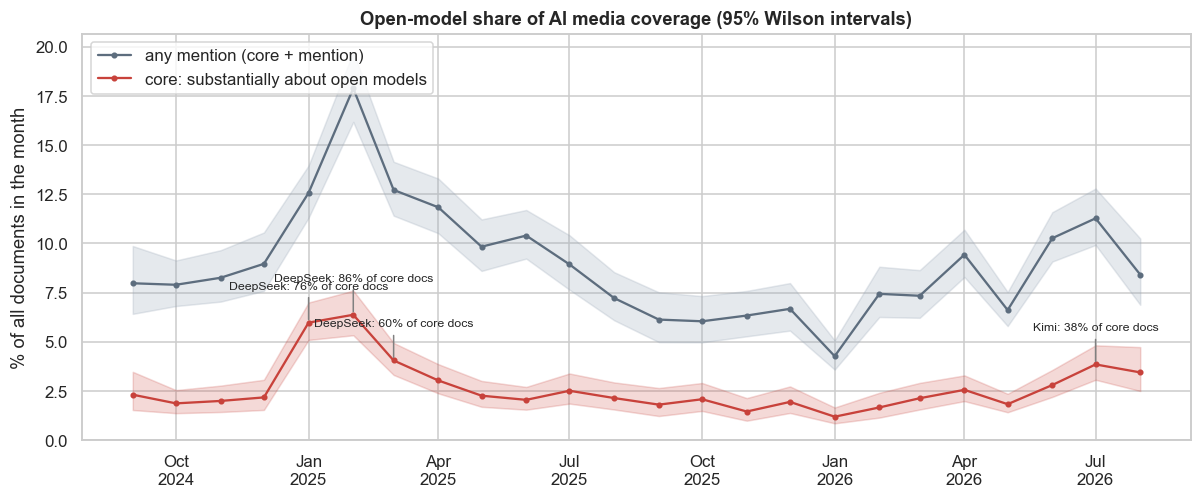

Mean monthly core share: first 12 months 3.06%, last 12 months 2.23%


In [19]:
def wilson(k, n, z=1.96):
    k, n = np.asarray(k, float), np.asarray(n, float)
    p = k / n
    den = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / den
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / den
    return centre - half, centre + half

monthly = (df.assign(core=df["om_tier"].eq("core"), anym=df["om_tier"].ne("none"))
             .groupby("month").agg(n=("doc_id", "size"), core=("core", "sum"), any_mention=("anym", "sum")))
monthly["core_share"], monthly["any_share"] = monthly["core"] / monthly["n"], monthly["any_mention"] / monthly["n"]
monthly["core_lo"], monthly["core_hi"] = wilson(monthly["core"], monthly["n"])
monthly["any_lo"], monthly["any_hi"] = wilson(monthly["any_mention"], monthly["n"])
save_table(monthly.round(4), "08_1_track_share_monthly", index=True)

fam_core = FAM_DOC[core_mask]
core_months = df.loc[core_mask, "month"].to_numpy()
overall_share = fam_core.mean()
peak_notes = {}
for m in monthly["core_share"].nlargest(4).index:
    sel = core_months == m
    share_m = fam_core[sel].mean()
    eligible = fam_core[sel].sum() >= 5
    lift = (share_m - overall_share)[eligible]
    if len(lift):
        f = lift.idxmax()
        peak_notes[m] = f"{FAMILY_LABEL[f]}: {share_m[f]:.0%} of core docs"
        top_titles = df.loc[core_mask].loc[sel].sort_values("om_score", ascending=False)["title"].head(3).tolist()
        print(f"{m} | core share {monthly.at[m, 'core_share']:.1%} | most over-represented family: {FAMILY_LABEL[f]} "
              f"({share_m[f]:.0%} vs {overall_share[f]:.0%} overall)\n    e.g. " + "\n    e.g. ".join(t[:110] for t in top_titles))

x = pd.to_datetime(monthly.index + "-01")
fig, ax = plt.subplots(figsize=(13, 4.8))
ax.fill_between(x, monthly["any_lo"] * 100, monthly["any_hi"] * 100, color="#9aa8b8", alpha=0.25)
ax.plot(x, monthly["any_share"] * 100, "-o", ms=3, color="#5d6d7e", label="any mention (core + mention)")
ax.fill_between(x, monthly["core_lo"] * 100, monthly["core_hi"] * 100, color="#c8423b", alpha=0.2)
ax.plot(x, monthly["core_share"] * 100, "-o", ms=3, color="#c8423b", label="core: substantially about open models")
for m, note in peak_notes.items():
    xm, ym = pd.Timestamp(m + "-01"), monthly.at[m, "core_share"] * 100
    ax.annotate(note, (xm, ym), xytext=(0, 22), textcoords="offset points", ha="center", fontsize=8,
                arrowprops=dict(arrowstyle="-", color="grey"))
ax.set_ylabel("% of all documents in the month"); ax.set_ylim(0, None)
ax.set_title("Open-model share of AI media coverage (95% Wilson intervals)")
ax.legend(loc="upper left"); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
save_fig(fig, "05_track_share_monthly")
first12, last12 = monthly["core_share"].iloc[:12], monthly["core_share"].iloc[12:]
print(f"Mean monthly core share: first 12 months {first12.mean():.2%}, last 12 months {last12.mean():.2%}")

**Q1 · Volume.**
* **Typical level:** open models are a niche but persistent part of AI coverage. In a typical month, 2–3 % of all documents are core and 6–10 % mention open models at all.
* **The DeepSeek shock, January–February 2025:**
  * the core share triples to 6.0 % and 6.4 %;
  * the any-mention share peaks at 17.9 %;
  * DeepSeek appears in 76–86 % of the core documents of those months.
  The wave carries into March (QwQ-32B, Aya Vision) and fades by May.
* **2026 recovery:** after a low in January 2026 (1.2 %), the share climbs again to 3.8 % in July 2026. Drivers are Kimi K3, coding-oriented open-weight models, and a policy debate about not over-regulating open-weight models.
* **Year-on-year:** the mean monthly core share fell from 3.1 % in year 1 to 2.2 % in year 2, while total volume grew slightly. This is consistent with open models becoming a routine part of AI news rather than a sensation.

### 8.2 Which model families get attention? (Q2)
The bars count **documents** that mention a family at least once, so repeated mentions inside one article count once. The darker part shows how many of those documents are *core*.

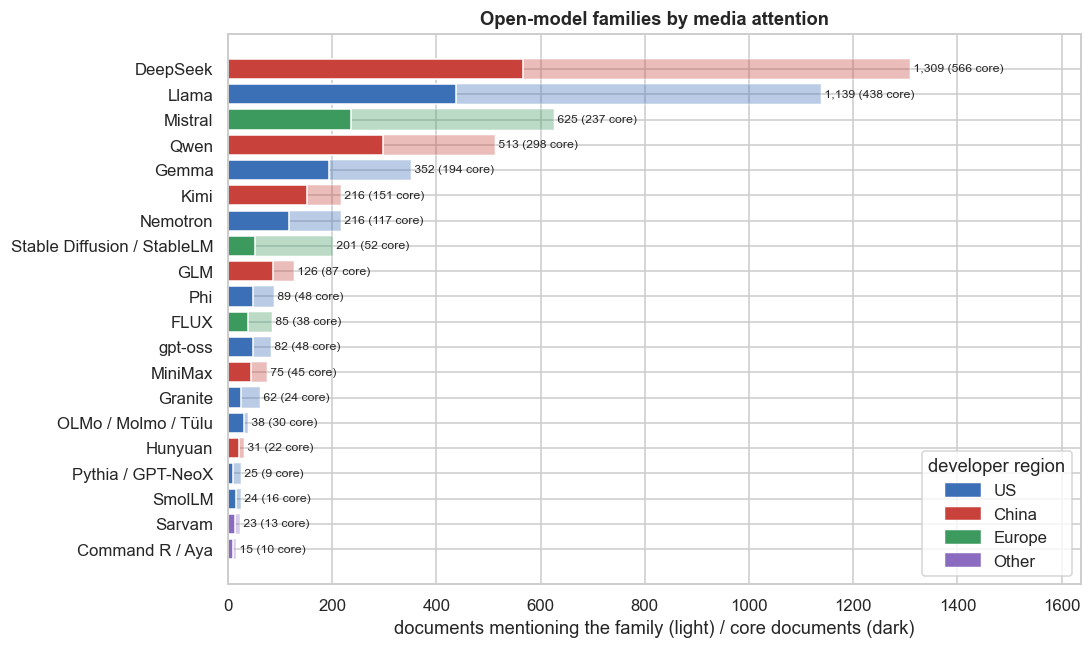

In [20]:
top20 = fam_counts.head(20)
fig, ax = plt.subplots(figsize=(10, 6.5))
colors = top20["region"].map(REGION_COLORS).tolist()
ax.barh(top20["label"][::-1], top20["docs_any"][::-1], color=colors[::-1], alpha=0.35)
ax.barh(top20["label"][::-1], top20["docs_core"][::-1], color=colors[::-1])
for y, (a, c_) in enumerate(zip(top20["docs_any"][::-1], top20["docs_core"][::-1])):
    ax.text(a, y, f" {a:,} ({c_:,} core)", va="center", fontsize=8)
ax.set_xlim(0, top20["docs_any"].max() * 1.25)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=v) for v in REGION_COLORS.values()], labels=list(REGION_COLORS), title="developer region")
ax.set_xlabel("documents mentioning the family (light) / core documents (dark)"); ax.set_title("Open-model families by media attention")
save_fig(fig, "06_family_ranking")

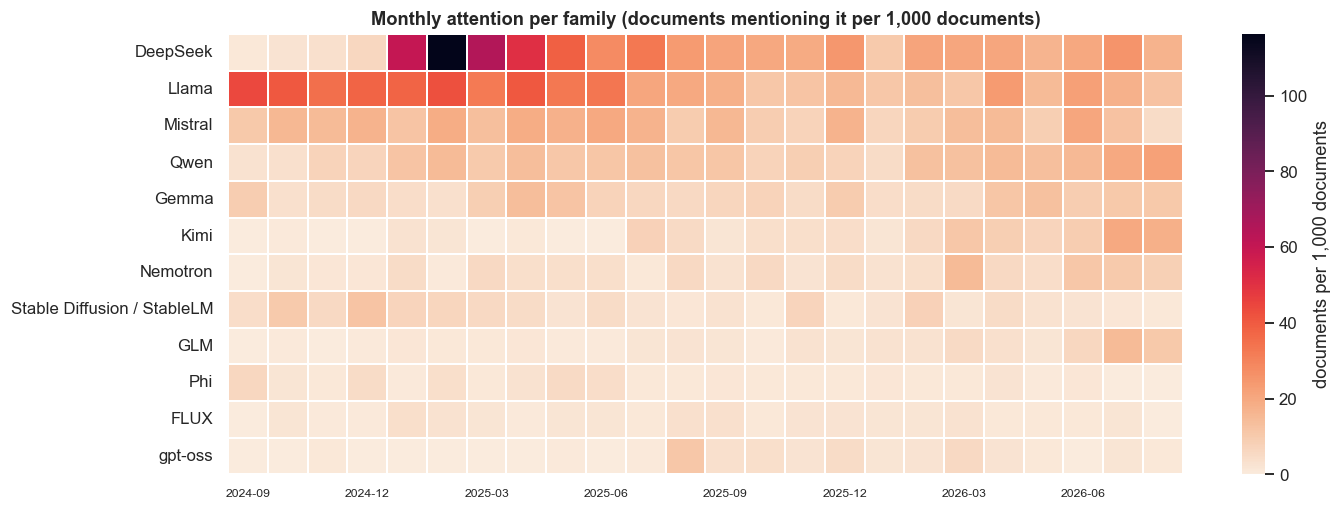

Peak month per family: {'DeepSeek': '2025-02 (116.3‰)', 'Llama': '2024-09 (44.1‰)', 'Mistral': '2026-06 (20.9‰)', 'Qwen': '2026-08 (22.0‰)', 'Gemma': '2025-04 (14.0‰)', 'Kimi': '2026-07 (19.8‰)', 'Nemotron': '2026-03 (14.6‰)', 'Stable Diffusion / StableLM': '2024-12 (11.9‰)', 'GLM': '2026-07 (15.0‰)', 'Phi': '2024-09 (6.3‰)', 'FLUX': '2025-01 (3.8‰)', 'gpt-oss': '2025-08 (11.0‰)'}


In [21]:
top12 = fam_counts.index[:12]
fm = FAM_DOC[top12].groupby(df["month"].to_numpy()).sum()
fm_rate = fm.div(df.groupby("month").size(), axis=0) * 1000
fm_rate.columns = [FAMILY_LABEL[k] for k in top12]
save_table(fm_rate.round(2), "08_2_family_monthly_per_1000_docs", index=True)
fig, ax = plt.subplots(figsize=(14, 5.2))
sns.heatmap(fm_rate.T, cmap="rocket_r", ax=ax, cbar_kws={"label": "documents per 1,000 documents"}, linewidths=0.3)
ax.set_xticks(np.arange(0, len(fm_rate), 3) + 0.5); ax.set_xticklabels(fm_rate.index[::3], rotation=0, fontsize=8)
ax.set_xlabel(""); ax.set_ylabel(""); ax.set_title("Monthly attention per family (documents mentioning it per 1,000 documents)")
save_fig(fig, "07_family_heatmap")
peak_month = fm_rate.idxmax()
print("Peak month per family:", {f: f"{peak_month[f]} ({fm_rate[f].max():.1f}‰)" for f in fm_rate.columns})

**Q2 · Actors.**
* **Concentration:** attention is highly concentrated. DeepSeek (1,309 documents) and Llama (1,139) appear about twice as often as the next family, Mistral (625).
* **Peaks over time:**
  * Llama's peak is at the start of the window (September 2024).
  * DeepSeek peaks in February 2025, when 11.6 % of *all* documents mention it.
  * gpt-oss, OpenAI's first open-weight release since GPT-2, peaks in August 2025.
  * 2026 belongs to the next wave: Nemotron (March), Mistral (June), Kimi and GLM (July) and Qwen (August).
* **Stable Diffusion** is visible (201 documents) but mostly outside the core (52), because it is usually discussed as a tool rather than as an open model.

### 8.3 United States, China, Europe: the regional balance (Q2)
Each family is assigned to its developer's home region. A document counts once for every region it mentions.

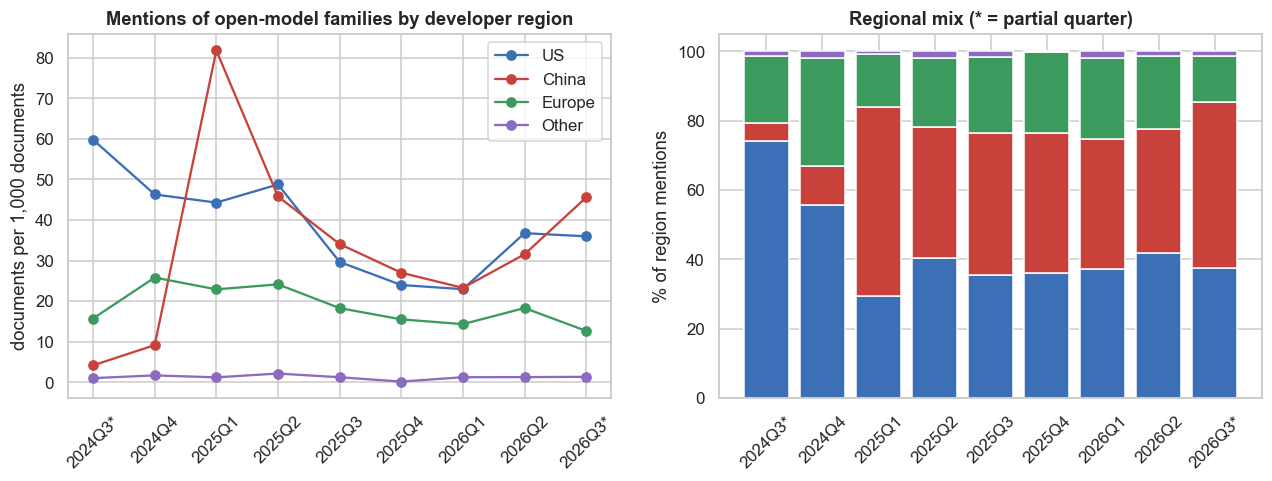

China/US ratio of documents per quarter: {'2024Q3': 0.07, '2024Q4': 0.2, '2025Q1': 1.85, '2025Q2': 0.94, '2025Q3': 1.15, '2025Q4': 1.13, '2026Q1': 1.01, '2026Q2': 0.86, '2026Q3': 1.27}


In [22]:
REGIONS = list(REGION_COLORS)
reg_doc = pd.DataFrame({r: FAM_DOC[[k for k in FAMILIES if FAMILY_REGION[k] == r]].any(axis=1) for r in REGIONS})
q_n = df.groupby("quarter").size()
q_reg = reg_doc.groupby(df["quarter"].to_numpy()).sum()
q_rate = q_reg.div(q_n, axis=0) * 1000
q_share = q_reg.div(q_reg.sum(axis=1), axis=0)
PARTIAL_Q = {"2024Q3", "2026Q3"}
qlab = [q + ("*" if q in PARTIAL_Q else "") for q in q_rate.index]
save_table(pd.concat([q_rate.add_suffix("_per_1000"), q_share.add_suffix("_share")], axis=1).round(3), "08_3_regions_quarterly", index=True)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.3))
for r in REGIONS:
    axes[0].plot(qlab, q_rate[r], "-o", color=REGION_COLORS[r], label=r)
axes[0].set_ylabel("documents per 1,000 documents"); axes[0].set_title("Mentions of open-model families by developer region"); axes[0].legend()
bottom = np.zeros(len(q_share))
for r in REGIONS:
    axes[1].bar(qlab, q_share[r] * 100, bottom=bottom, color=REGION_COLORS[r], label=r)
    bottom += q_share[r].to_numpy() * 100
axes[1].set_ylabel("% of region mentions"); axes[1].set_title("Regional mix (* = partial quarter)")
for a in axes:
    a.tick_params(axis="x", labelrotation=45)
save_fig(fig, "08_regions_quarterly")
print("China/US ratio of documents per quarter:", (q_reg["China"] / q_reg["US"]).round(2).to_dict())

**Q2 · Regional balance.**
* **Late 2024:** coverage is overwhelmingly about US families. In Q4 2024 there are only 0.2 documents on Chinese families for every document on US families.
* **Q1 2025:** DeepSeek reverses this. The ratio jumps to 1.85, and Chinese families receive 54 % of region mentions.
* **Q3 2025 – Q1 2026:** Chinese and US families are mentioned about equally often (ratio 1.0–1.15).
* **July–August 2026:** Chinese families lead again (48 % vs 38 %), driven by Kimi, GLM and Qwen.
* **Europe:** essentially Mistral and Stable Diffusion, holding 15–23 % of region mentions from 2025 to mid-2026 (13 % in July–August 2026).

The open-model discourse turned into a US–China story in early 2025 and did not return to its US-centred starting point.

### 8.4 Release radar: when do model versions first appear? (Q3)
Version strings such as *Llama 4*, *Qwen 3*, *DeepSeek R1*, *Kimi K2* or *GLM-4.5* are extracted with family-specific patterns. For each version the table gives the date it was **first seen** in the corpus, its **peak month** and the number of documents.

Two clocks must not be confused (Course 3, Course 4). First-seen is a *publication* date: an upper bound for the announcement, not the release date. Versions already in circulation when the window opens appear at its left edge. The table is a candidate list of `MODEL` entities with temporal qualifiers for WP2/WP3.

68 versions with ≥ 5 documents; 59 first appear inside the window.


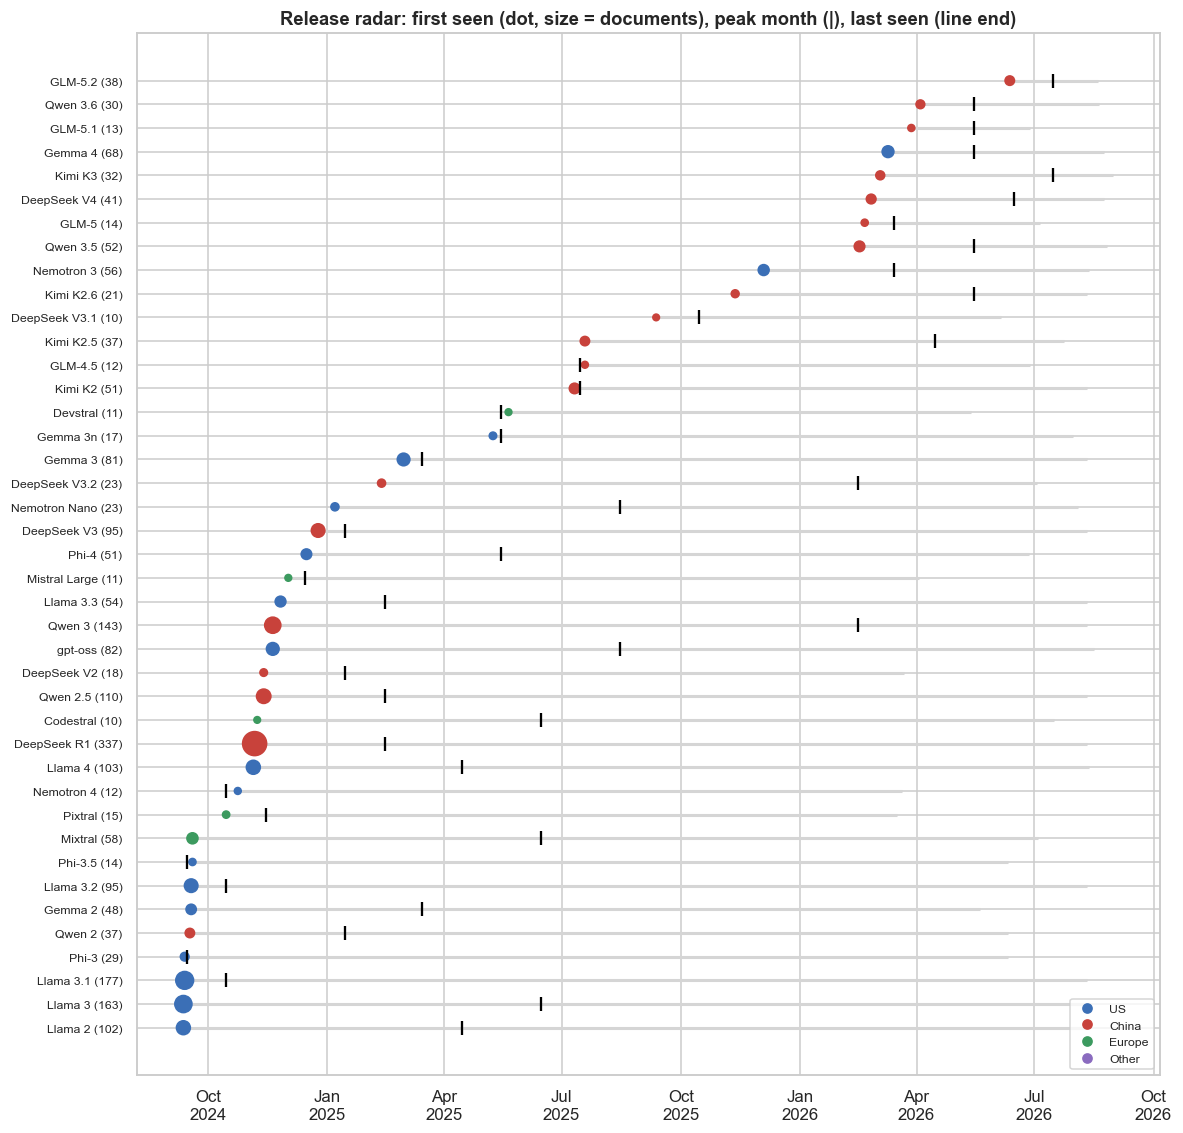

,family,n_docs,first_seen,peak_month
version,,,,
DeepSeek R1,deepseek,337,2024-11-06,2025-02
Qwen 3,qwen,143,2024-11-20,2026-02
Qwen 2.5,qwen,110,2024-11-13,2025-02
Llama 4,llama,103,2024-11-05,2025-04
DeepSeek V3,deepseek,95,2024-12-25,2025-01
gpt-oss,gpt_oss,82,2024-11-20,2025-08
Gemma 3,gemma,81,2025-03-01,2025-03
Gemma 4,gemma,68,2026-03-10,2026-05
Nemotron 3,nemotron,56,2025-12-04,2026-03


In [23]:
VERSION_PATTERNS = [
    ("llama", re.compile(r"\b(?:Llama|LLaMA|LLAMA)[- ]?(\d(?:\.\d)?)(?![\d.])(?!\s?[BbMm]\b)"), "Llama {}"),
    ("qwen", re.compile(r"\bQwen[- ]?(\d(?:\.\d)?)(?![\d.])(?!\s?[BbMm]\b)"), "Qwen {}"),
    ("deepseek", re.compile(r"\b(?:DeepSeek|Deepseek)[- ]?((?:R|V)\d(?:\.\d)?)\b"), "DeepSeek {}"),
    ("gemma", re.compile(r"\bGemma[- ]?(\dn?)\b(?![\d.])"), "Gemma {}"),
    ("phi", re.compile(r"\bPhi[- ]?(\d(?:\.5)?)\b"), "Phi-{}"),
    ("kimi", re.compile(r"\bKimi[- ]?(K\d(?:\.\d)?)\b"), "Kimi {}"),
    ("glm", re.compile(r"\bGLM[- ]?(\d(?:\.\d)?)\b"), "GLM-{}"),
    ("minimax", re.compile(r"\bMiniMax[- ]?(M\d(?:\.\d)?)\b"), "MiniMax-{}"),
    ("mistral", re.compile(r"\bMistral (Small|Medium|Large)(?: (\d(?:\.\d)?))?\b"), "Mistral {}"),
    ("mistral", re.compile(r"\b(Mixtral|Magistral|Devstral|Codestral|Pixtral|Ministral|Voxtral)\b"), "{}"),
    ("gpt_oss", re.compile(r"(?i)\bgpt[- ]oss\b"), "gpt-oss"),
    ("nemotron", re.compile(r"\bNemotron[- ](\d(?:\.\d)?|Nano|Super|Ultra)\b"), "Nemotron {}"),
    ("granite", re.compile(r"\bGranite[- ]?(\d(?:\.\d)?)\b"), "Granite {}"),
    ("olmo", re.compile(r"\b(?:OLMo|Olmo)[- ]?(\d)\b"), "OLMo {}"),
    ("apertus", re.compile(r"\bApertus\b"), "Apertus"),
]
rows = []
for fam, rx, fmt in VERSION_PATTERNS:
    for i in np.flatnonzero(FAM_DOC[fam].to_numpy()):
        s = match_view(df["title"].iat[i] + "\n\n" + df["text"].iat[i])
        found = {fmt.format(" ".join(g for g in m.groups() if g)).strip() if rx.groups else fmt for m in rx.finditer(s)}
        rows += [(fam, lab, df["date"].iat[i], df["month"].iat[i], df["doc_id"].iat[i]) for lab in found]
vm = pd.DataFrame(rows, columns=["family", "version", "date", "month", "doc_id"]).drop_duplicates(["version", "doc_id"])
versions = (vm.groupby("version").agg(family=("family", "first"), n_docs=("doc_id", "nunique"), first_seen=("date", "min"),
                                      last_seen=("date", "max"), peak_month=("month", lambda s: s.value_counts().idxmax()))
              .query("n_docs >= 5").sort_values("first_seen"))
versions["region"] = versions["family"].map(FAMILY_REGION)
versions["in_circulation_at_window_start"] = versions["first_seen"] < STUDY_START + pd.Timedelta(days=21)
save_table(versions.reset_index().assign(first_seen=lambda d: d["first_seen"].dt.date, last_seen=lambda d: d["last_seen"].dt.date),
           "08_4_model_versions_first_seen")
print(f"{len(versions)} versions with ≥ 5 documents; {int((~versions['in_circulation_at_window_start']).sum())} first appear inside the window.")

vt = versions[versions["n_docs"] >= 10].sort_values("first_seen")
fig, ax = plt.subplots(figsize=(12, max(4, 0.3 * len(vt))))
yy = np.arange(len(vt))
ax.hlines(yy, vt["first_seen"], vt["last_seen"], color="#d5d5d5", lw=2)
ax.scatter(vt["first_seen"], yy, s=vt["n_docs"].clip(upper=500) * 0.7 + 12, c=vt["region"].map(REGION_COLORS).tolist(), zorder=3)
ax.scatter(pd.to_datetime(vt["peak_month"] + "-15"), yy, marker="|", s=90, color="black", zorder=4)
ax.set_yticks(yy); ax.set_yticklabels([f"{v} ({n})" for v, n in zip(vt.index, vt["n_docs"])], fontsize=8)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
ax.set_title("Release radar: first seen (dot, size = documents), peak month (|), last seen (line end)")
ax.legend(handles=[plt.Line2D([], [], marker="o", ls="", color=v) for v in REGION_COLORS.values()], labels=list(REGION_COLORS),
          loc="lower right", fontsize=8)
save_fig(fig, "09_release_radar")
display(vt.loc[~vt["in_circulation_at_window_start"], ["family", "n_docs", "first_seen", "peak_month"]].sort_values("n_docs", ascending=False).head(15))

**Q3 · Releases.**
* **Coverage:** 68 model versions reach at least 5 documents, and 59 of them first appear inside the window.
* **Peaks follow releases:**
  * DeepSeek R1 (337 documents, released January 2025) peaks in February 2025;
  * Llama 4 (103) peaks in April 2025;
  * Kimi K2 (51) peaks in July 2025;
  * gpt-oss (82) peaks in August 2025.
* **The release cadence accelerates:** in 2026, Qwen 3.5 and 3.6, Gemma 4, DeepSeek V4, Kimi K3 and the GLM-5.x line appear within a few months of each other.
* **First-seen dates are not release dates.** gpt-oss and Qwen 3 are first seen in documents dated November 2024, months before their release. This most likely reflects continuously updated pages (model catalogues, documentation) that keep an older publication date.
* **For the knowledge graph:** publication time and event time are different clocks. WP2 should extract event dates from the text, and treat a document's date as an upper bound only for news articles.

### 8.5 Words for openness: *open-weight* vs *open-source* (Q5)
How the media name openness is itself a finding. *Open-source model* is the older, looser term. *Open-weight* is more precise and is preferred by people who follow the OSI definition. We track the share of documents using each term, and the share of *open-weight* among all *open-weight* + *open-source model* mentions.

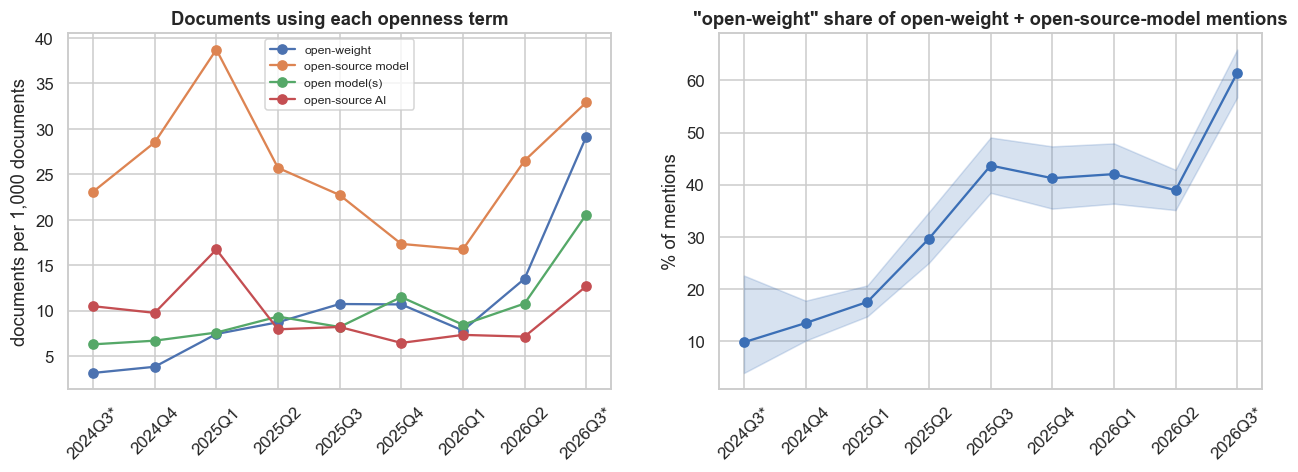

Open-weight share by quarter: {'2024Q3': 0.098, '2024Q4': 0.134, '2025Q1': 0.175, '2025Q2': 0.296, '2025Q3': 0.437, '2025Q4': 0.412, '2026Q1': 0.42, '2026Q2': 0.389, '2026Q3': 0.614}


In [24]:
TERMS = {"open-weight": "open_weight", "open-source model": "open_source_model", "open model(s)": "open_model", "open-source AI": "open_source_ai"}
term_q = pd.DataFrame({lab: (C_total[col] > 0).groupby(df["quarter"].to_numpy()).sum() for lab, col in TERMS.items()})
term_rate = term_q.div(q_n, axis=0) * 1000
ow = C_total["open_weight"].groupby(df["quarter"].to_numpy()).sum()
osm = C_total["open_source_model"].groupby(df["quarter"].to_numpy()).sum()
ow_share = ow / (ow + osm)
lo, hi = wilson(ow, ow + osm)
save_table(term_rate.assign(open_weight_share=ow_share).round(3), "08_5_terminology_quarterly", index=True)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for lab in TERMS:
    axes[0].plot(qlab, term_rate[lab], "-o", label=lab)
axes[0].set_ylabel("documents per 1,000 documents"); axes[0].set_title("Documents using each openness term"); axes[0].legend(fontsize=8)
xq_t = np.arange(len(qlab))
axes[1].fill_between(xq_t, lo * 100, hi * 100, color="#3b6fb6", alpha=0.2)
axes[1].plot(xq_t, ow_share.to_numpy() * 100, "-o", color="#3b6fb6")
axes[1].set_xticks(xq_t); axes[1].set_xticklabels(qlab)
axes[1].set_ylabel("% of mentions"); axes[1].set_title('"open-weight" share of open-weight + open-source-model mentions')
for a in axes:
    a.tick_params(axis="x", labelrotation=45)
save_fig(fig, "10_terminology")
print("Open-weight share by quarter:", ow_share.round(3).to_dict())

**Q5 · Terminology.**
* *Open-source model* remains the more common term overall.
* The share of *open-weight* rose steadily:
  * 10–13 % in late 2024;
  * 30 % in Q2 2025;
  * about 40 % from Q3 2025;
  * 61 % in July–August 2026 (partial quarter).
* Media vocabulary is converging on the more precise term. This is consistent with the OSI definition debate and with OpenAI describing gpt-oss as open-weight.
* **For the knowledge graph** this is a normalisation issue (Course 1: one concept, several forms). Both terms should map to the same openness attribute, with the original wording kept as evidence.

## 9. Preprocessing for topic modelling (analysis view)
Topic models need a different representation from NER (Course 2: *every transformation asserts an invariance*). For the **core** subset we build the analysis view in four steps:

1. **Phrase and acronym normalisation** before tokenisation, so that spelling variants become one token. This gives the consistent acronym representation the project brief asks for:
   * *open-weight / open weights* → `open_weight`; *open-source* → `open_source`
   * *large language model(s) / LLMs* → `llm`; *small language model / SLM* → `slm`
   * *mixture-of-experts / MoE* → `mixture_of_experts`; *fine-tuning / finetuning* → `fine_tuning`
   * *chain of thought / CoT* → `chain_of_thought`; *reasoning model* → `reasoning_model`
   * *U.S. / United States* → `united_states`; *export controls* → `export_control`; *Hugging Face* → `hugging_face`
2. **Model-name canonicalisation** with the lexicon: *Llama-3.1-8B-Instruct*, *LLaMA* and *Code Llama* all become the family token `llama`, and *Qwen2.5-Max* and *QwQ* become `qwen`. Versions are analysed separately in 8.4.
3. **spaCy `en_core_web_sm`** tokenisation, POS tagging and lemmatisation. We keep nouns, proper nouns, adjectives and verbs, plus the protected tokens from steps 1–2.
4. **Removal** of spaCy stop words, numbers, parameter sizes (*8b*, *70b*), one-letter tokens and a short list of reporting verbs and fillers. Frequent generic words are removed later by the vectoriser (`max_df = 0.5`) instead of a hand-made list.

Documents are truncated to 12,000 characters (about 2,000 words) to bound run time. The median clean document is shorter, and a news article states its subject early. Lemmas are cached per document in `data/processed/lemma_cache.parquet` and invalidated when the preprocessing code changes.

In [25]:
PHRASES = [(re.compile(p), rep) for p, rep in [
    (r"(?i)\bopen[- ]?weights?\b", " open_weight "), (r"(?i)\bopen[- ]?sourced?\b", " open_source "),
    (r"(?i)\blarge language models?\b|\bLLMs?\b", " llm "), (r"(?i)\bsmall language models?\b|\bSLMs?\b", " slm "),
    (r"(?i)\bmixture[- ]of[- ]experts?\b|\bMoE\b", " mixture_of_experts "), (r"(?i)\bfine[- ]?tun(?:e|es|ed|ing)\b", " fine_tuning "),
    (r"(?i)\bchain[- ]of[- ]thought\b|\bCoT\b", " chain_of_thought "), (r"(?i)\breasoning models?\b", " reasoning_model "),
    (r"(?i)\bfoundation models?\b", " foundation_model "), (r"(?i)\bgenerative ai\b|\bgen ?ai\b", " generative_ai "),
    (r"(?i)\bartificial intelligence\b", " ai "), (r"\bU\.S\.(?:A\.)?|\bUSA?\b|\bUnited States\b", " united_states "),
    (r"(?i)\bexport controls?\b", " export_control "), (r"(?i)\bnational security\b", " national_security "),
    (r"(?i)\bdata cent(?:er|re)s?\b", " data_center "), (r"(?i)\bhugging ?face\b", " hugging_face "), (r"(?i)\bopen ai\b", " openai "),
]]
PROTECTED = set(FAMILIES) | {rep.strip() for _, rep in PHRASES}
KEEP_POS = {"NOUN", "PROPN", "ADJ", "VERB"}
EXTRA_STOP = set("say tell accord according include also use make get go come take give know think want see look need help let put seem become "
                 "mr ms inc ltd co etc lot thing way year month week day time today new many much more most other such same own able likely "
                 "recent recently late early first last next previous well good great big small large high low https http www com html".split())
PARAM_RX, HAS_ALPHA = re.compile(r"^\d+(?:\.\d+)?[bmkt]$"), re.compile(r"[a-z]")

def analysis_view(title, text):
    s = match_view(title + ".\n\n" + text)[:SPACY_MAX_CHARS]
    for k, spec in FAMILIES.items():
        if any(kw in s for kw in spec["kw"]):
            s = FAM_RX[k].sub(f" {k} ", s)
    for rx, rep in PHRASES:
        s = rx.sub(rep, s)
    return s

try:
    nlp = spacy.load("en_core_web_sm", disable=["parser", "ner"])
except OSError:
    from spacy.cli import download
    download("en_core_web_sm")
    nlp = spacy.load("en_core_web_sm", disable=["parser", "ner"])
nlp.max_length = SPACY_MAX_CHARS * 3
SPACY_STOP = nlp.Defaults.stop_words

def lemmatise(doc):
    out = []
    for tok in doc:
        low = tok.text.lower()
        if low in PROTECTED:
            out.append(low)
            continue
        if tok.is_space or tok.is_punct or tok.is_stop or tok.like_num or tok.pos_ not in KEEP_POS:
            continue
        lem = tok.lemma_.lower().strip(" -'\".")
        if len(lem) < 2 or not HAS_ALPHA.search(lem) or lem in EXTRA_STOP or lem in SPACY_STOP or PARAM_RX.match(lem):
            continue
        out.append(lem)
    return out

core_idx = np.flatnonzero(core_mask)
core = df.loc[core_mask].reset_index(drop=True)
PREPROC_VERSION = hashlib.sha1(json.dumps([[p.pattern, r] for p, r in PHRASES] + [sorted(PROTECTED), sorted(KEEP_POS), sorted(EXTRA_STOP),
                                            SPACY_MAX_CHARS, LEXICON_HASH, spacy.__version__]).encode()).hexdigest()[:12]
LEMMA_PATH = DATA_PROCESSED / "lemma_cache.parquet"     # per-document cache, safe to resume after an interruption
cache = pd.read_parquet(LEMMA_PATH) if LEMMA_PATH.exists() and not FORCE_REBUILD else pd.DataFrame(columns=["doc_id", "lemmas", "preproc_version"])
cache = cache[cache["preproc_version"] == PREPROC_VERSION]
done = dict(zip(cache["doc_id"], cache["lemmas"]))
todo = core.loc[~core["doc_id"].isin(set(done)), ["doc_id", "title", "text"]]
t0 = time.time()
for start in range(0, len(todo), 200):
    chunk = todo.iloc[start:start + 200]
    views = [analysis_view(t, b) for t, b in zip(chunk["title"], chunk["text"])]
    for doc_id, d in zip(chunk["doc_id"], nlp.pipe(views, batch_size=32)):
        done[doc_id] = " ".join(lemmatise(d))
    pd.DataFrame({"doc_id": list(done), "lemmas": list(done.values())}).assign(preproc_version=PREPROC_VERSION).to_parquet(LEMMA_PATH, index=False)
core["lemmas"] = core["doc_id"].map(done)
print(f"Lemmas: {len(core) - len(todo):,} core documents from cache, {len(todo):,} lemmatised now in {time.time() - t0:.0f}s")
n_tok = core["lemmas"].str.split().str.len()
print(f"Tokens per document after preprocessing: median {n_tok.median():.0f} | vocabulary {len(set(' '.join(core['lemmas']).split())):,} types")
ex = core.sort_values("om_score", ascending=False).iloc[0]
print("\nEXAMPLE —", ex["title"])
print("fidelity text :", ex["text"][:260].replace("\n", " "))
print("analysis view :", " ".join(ex["lemmas"].split()[:45]))

Lemmas: 1,210 core documents from cache, 0 lemmatised now in 0s
Tokens per document after preprocessing: median 624 | vocabulary 26,729 types

EXAMPLE — Alibaba’s new open source model QwQ-32B matches DeepSeek-R1 with way smaller compute requirements
fidelity text : Qwen Team — a division of Chinese e-commerce giant Alibaba developing its growing family of open-source Qwen large language models (LLMs) — has introduced QwQ-32B, a new 32-billion-parameter reasoning model designed to improve performance on complex problem-so
analysis view : alibaba open_source model qwen match deepseek r1 compute requirement qwen team division chinese commerce giant alibaba develop grow family open_source qwen llm llm introduce qwen parameter reasoning_model design improve performance complex problem solve task reinforcement learning rl model available open_weight hugging_face modelscope apache license mean


## 10. Sentiment and framing (Q5)
Document-level sentiment of news is close to neutral and says little about open models in particular. We therefore work at **sentence level, on target sentences**: sentences in core documents that mention an open-model family or an openness concept. Sentences are split with a rule (sentence-final punctuation followed by a capital letter, plus paragraph breaks), and WP2 can re-segment with a parser if needed.

* **Sentiment**: VADER compound score (−1 … +1). It is lexicon-based, transparent and fast. It is not trained on news and does not understand domain words, so we report averages with confidence intervals and show the extreme sentences as a check.
* **Framing**: a transparent keyword dictionary with seven frames: performance and benchmarks, cost and efficiency, access and democratisation, safety and misuse, geopolitics and sovereignty, licensing and definitions, enterprise adoption. A sentence can carry several frames. Frame shares tell us what open models are talked about *in terms of*, which is closer to stance than polarity.

In [26]:
nltk.download("vader_lexicon", quiet=True)
from nltk.sentiment import SentimentIntensityAnalyzer
sia = SentimentIntensityAnalyzer()
SENT_SPLIT = re.compile(r"(?<=[.!?])\s+(?=[\"'(\[A-Z0-9])|\n{2,}")
FRAMES = {
    "Performance & benchmarks": r"\b(?:benchmark\w*|outperform\w*|state[- ]of[- ]the[- ]art|leaderboard\w*|beats?|rivals?|rivall?ing|on par|surpass\w*|frontier|top[- ]performing)\b",
    "Cost & efficiency": r"\b(?:cost\w*|cheap\w*|efficien\w*|afford\w*|pric(?:e|es|ed|ing)|fraction of|inexpensive|low[- ]cost|budget\w*)\b",
    "Access & democratisation": r"\b(?:democrati[sz]\w*|accessib\w*|transparen\w*|communit(?:y|ies)|collaborat\w*|freely|free to|researchers?|anyone|permissive\w*|download\w*|locally|on[- ]device)\b",
    "Safety & misuse": r"\b(?:risk\w*|misuse\w*|safety|unsafe|danger\w*|harm\w*|malicious|jailbreak\w*|bioweapon\w*|weapon\w*|guardrail\w*|vulnerab\w*|abus(?:e|ed|es|ing)|threat\w*)\b",
    "Geopolitics & sovereignty": r"\b(?:china|chinese|beijing|u\.s\.|united states|america\w*|export controls?|national security|geopolit\w*|sovereign\w*|bans?|banned|sanction\w*|military|ai race)\b",
    "Licensing & definitions": r"\b(?:licen[cs]\w*|apache|osi|open source initiative|definition|open[- ]?washing|terms of use|commercial use|restrict\w*|proprietary|closed[- ]source|closed models?)\b",
    "Enterprise adoption": r"\b(?:enterprise\w*|customers?|deploy\w*|production|adopt\w*|integrat\w*|on[- ]prem\w*|workloads?|businesses)\b",
}
FRAME_RX = {k: re.compile(v) for k, v in FRAMES.items()}

t0 = time.time()
TICKER_RX = re.compile(r"\s*\([A-Z.]{1,6} Quick Quote[A-Z.]{1,6} - Free Report\)")   # inline stock-ticker boilerplate
rows = []
for doc_id, date, text in zip(core["doc_id"], core["date"], core["text"]):
    for j, sent in enumerate(SENT_SPLIT.split(match_view(text))):
        sent = TICKER_RX.sub("", sent).strip()
        if not 40 <= len(sent) <= 600:
            continue
        low = sent.lower()
        fams = [k for k, spec in FAMILIES.items() if any(kw in sent for kw in spec["kw"]) and FAM_RX[k].search(sent)]
        cons = [k for k, spec in CONCEPTS.items() if any(kw in low for kw in spec["kw"]) and CON_RX[k].search(sent)]
        if fams or cons:
            rows.append((doc_id, date, j, sent, fams, cons))
sent_df = pd.DataFrame(rows, columns=["doc_id", "date", "sent_idx", "sentence", "families", "concepts"])
sent_df["vader_compound"] = [sia.polarity_scores(s)["compound"] for s in sent_df["sentence"]]
lows = sent_df["sentence"].str.lower()
for frame, rx in FRAME_RX.items():
    sent_df[frame] = [bool(rx.search(s)) for s in lows]
sent_df["quarter"] = sent_df["date"].dt.to_period("Q").astype(str)
sent_df["regions"] = sent_df["families"].map(lambda fs: sorted({FAMILY_REGION[f] for f in fs}))
print(f"{len(sent_df):,} target sentences from {sent_df['doc_id'].nunique():,} core documents ({time.time() - t0:.0f}s)")
print(f"Mean compound {sent_df['vader_compound'].mean():+.3f} | positive (≥ 0.05) {(sent_df['vader_compound'] >= 0.05).mean():.0%} | "
      f"negative (≤ −0.05) {(sent_df['vader_compound'] <= -0.05).mean():.0%}")

13,587 target sentences from 1,207 core documents (6s)
Mean compound +0.237 | positive (≥ 0.05) 56% | negative (≤ −0.05) 10%


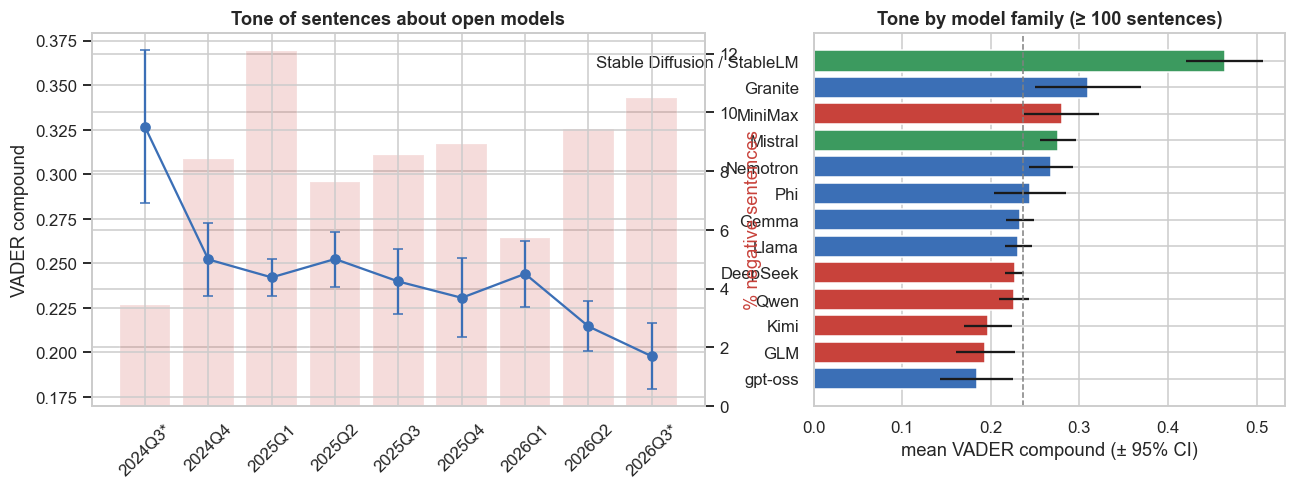

Most positive:
  +0.95 | But the same efficiency gains that allow smaller actors like DeepSeek to access a given capability (" access effect ") will probably also allow other 
  +0.95 | Alpamayo 2 Super is part of NVIDIA's growing collection of open models, datasets and tools for autonomous driving, expanding access, strengthening com
  +0.95 | This robust financial backing and strategic partnerships have attracted prominent European clients like BNP Paribas, AXA, Stellantis, and CMA CGM, who
Most negative:
  -0.91 | Opposition by developers helped to block California SB 1047, a proposed law that would have held developers of models above certain size limits liable
  -0.90 | As seen in Figure 1, when presented with over 400 different crisis scenarios built to match the Militarized Interstate Dispute Dataset—an authoritativ
  -0.90 | But, critics fear that open-source models can expose security vulnerabilities that could be exploited, which we've already seen in DeepSeek's first we


In [27]:
q_sent = sent_df.groupby("quarter")["vader_compound"].agg(["mean", "std", "count"])
q_sent["ci"] = 1.96 * q_sent["std"] / np.sqrt(q_sent["count"])
q_sent["neg_share"] = sent_df.groupby("quarter")["vader_compound"].apply(lambda s: (s <= -0.05).mean())
fam_sent = []
for k in fam_counts.index[:14]:
    s_ = sent_df.loc[sent_df["families"].map(lambda fs, k=k: k in fs), "vader_compound"]
    if len(s_) >= 100:
        fam_sent.append([FAMILY_LABEL[k], FAMILY_REGION[k], len(s_), s_.mean(), 1.96 * s_.std() / np.sqrt(len(s_))])
fam_sent = pd.DataFrame(fam_sent, columns=["family", "region", "sentences", "mean_compound", "ci"]).sort_values("mean_compound")
save_table(q_sent.round(4), "10_sentiment_quarterly", index=True); save_table(fam_sent.round(4), "10_sentiment_by_family")
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4), gridspec_kw={"width_ratios": [1.3, 1]})
xq = np.arange(len(q_sent))
axes[0].errorbar(xq, q_sent["mean"], yerr=q_sent["ci"], fmt="-o", color="#3b6fb6", capsize=3, label="mean compound ± 95% CI")
ax2 = axes[0].twinx()
ax2.bar(xq, q_sent["neg_share"] * 100, color="#c8423b", alpha=0.18, label="% negative sentences")
ax2.set_ylabel("% negative sentences", color="#c8423b")
axes[0].set_xticks(xq); axes[0].set_xticklabels([q + ("*" if q in PARTIAL_Q else "") for q in q_sent.index], rotation=45)
axes[0].set_ylabel("VADER compound"); axes[0].set_title("Tone of sentences about open models")
axes[0].set_zorder(ax2.get_zorder() + 1); axes[0].patch.set_visible(False)
axes[1].barh(fam_sent["family"], fam_sent["mean_compound"], xerr=fam_sent["ci"], color=fam_sent["region"].map(REGION_COLORS).tolist())
axes[1].axvline(sent_df["vader_compound"].mean(), color="grey", ls="--", lw=1)
axes[1].set_xlabel("mean VADER compound (± 95% CI)"); axes[1].set_title("Tone by model family (≥ 100 sentences)")
save_fig(fig, "11_sentiment")
show = lambda d: [f"{r.vader_compound:+.2f} | {r.sentence[:150]}" for r in d.itertuples()]
print("Most positive:", *show(sent_df.nlargest(3, "vader_compound")), sep="\n  ")
print("Most negative:", *show(sent_df.nsmallest(3, "vader_compound")), sep="\n  ")

**Q5 · Tone.**
* **Overall:** sentences about open models are mostly positive. 56 % are positive and 10 % negative, with a mean compound score of +0.24.
* **Over time:** tone declines slowly, from about +0.25 in late 2024 to +0.20 in mid-2026. The negative share is highest in Q1 2025 (12 %), the DeepSeek quarter, when admiration for efficiency met security and market fears.
* **By family:**
  * Stable Diffusion is the most positive (+0.46, creative tooling);
  * Mistral (+0.28) and Nemotron (+0.27) are above average;
  * gpt-oss, GLM and Kimi are the least positive (+0.18 to +0.20).
  * Apart from Stable Diffusion, the differences are small.
* **Caveat:** VADER reads news language literally. The most negative sentences include a report about *crisis scenarios* in a benchmark as well as genuine security concerns. These values are indicative; a trained stance classifier (Stage 2) would be the next step.

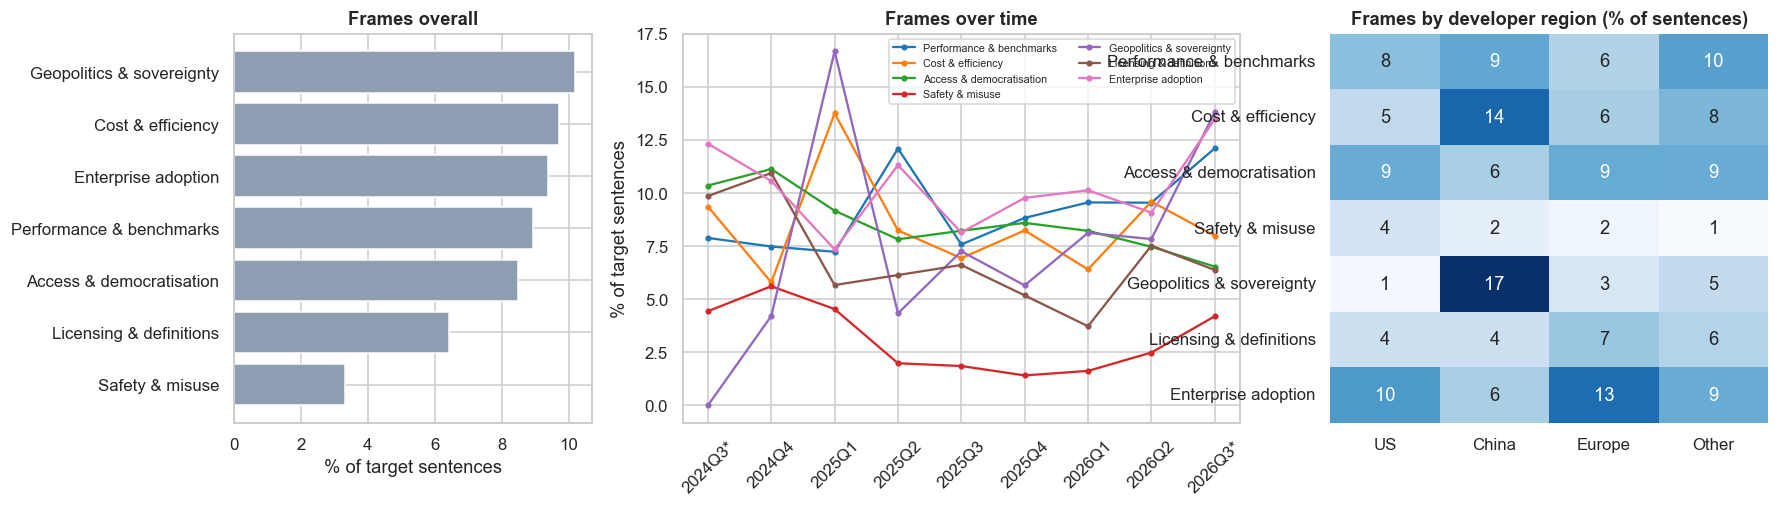

Sentences mentioning one region only: {'China': 5982, 'US': 3915, 'Europe': 991, 'Other': 121}
Example [Safety & misuse]: Part 1 looks at GenAI's impact on risk management frameworks while this piece examines DeepSeek's initial impact on the LLM market.
Example [Geopolitics & sovereignty]: In fact, booming demand for DeepSeek's low-cost AI models is providing a boost to NVIDIA as Chinese companies are ramping up orders for NVIDIA's H20 artificial intelligen
Example [Licensing & definitions]: GLM-5,2 is also one-fifth the price of comparable closed models.


In [28]:
FR = list(FRAMES)
frame_all = (sent_df[FR].mean() * 100).sort_values()
frame_q = sent_df.groupby("quarter")[FR].mean() * 100
single = sent_df[sent_df["regions"].map(len) == 1].copy()
single["region"] = single["regions"].str[0]
frame_reg = single.groupby("region")[FR].mean().reindex(["US", "China", "Europe", "Other"]) * 100
save_table(frame_q.round(2), "10_frames_quarterly", index=True); save_table(frame_reg.round(2), "10_frames_by_region", index=True)
fig, axes = plt.subplots(1, 3, figsize=(18, 4.6), gridspec_kw={"width_ratios": [0.9, 1.4, 1.1]})
axes[0].barh(frame_all.index, frame_all.values, color="#8f9db3"); axes[0].set_xlabel("% of target sentences"); axes[0].set_title("Frames overall")
pal = sns.color_palette("tab10", len(FR))
for c_, f in zip(pal, FR):
    axes[1].plot(np.arange(len(frame_q)), frame_q[f], "-o", ms=3, color=c_, label=f)
axes[1].set_xticks(np.arange(len(frame_q))); axes[1].set_xticklabels([q + ("*" if q in PARTIAL_Q else "") for q in frame_q.index], rotation=45)
axes[1].set_ylabel("% of target sentences"); axes[1].set_title("Frames over time"); axes[1].legend(fontsize=7, ncol=2)
sns.heatmap(frame_reg.T, annot=True, fmt=".0f", cmap="Blues", ax=axes[2], cbar=False)
axes[2].set_title("Frames by developer region (% of sentences)"); axes[2].set_xlabel(""); axes[2].set_ylabel("")
save_fig(fig, "12_frames")
print("Sentences mentioning one region only:", single["region"].value_counts().to_dict())
for f in ["Safety & misuse", "Geopolitics & sovereignty", "Licensing & definitions"]:
    ex_ = sent_df[sent_df[f]].sample(1, random_state=SEED).iloc[0]
    print(f"Example [{f}]: {ex_['sentence'][:170]}")

**Q5 · Framing.**
* **Overall, no single frame dominates.** Geopolitics and sovereignty (about 10 % of target sentences), cost and efficiency (10 %), enterprise adoption (9 %), performance (9 %) and access (8.5 %) are close. Licensing (6 %) and safety and misuse (3 %) are rarer.
* **The framing is strongly regional:**
  * Chinese models are discussed in terms of geopolitics (17 % of sentences, vs 1 % for US models) and cost (14 % vs 5 %);
  * US and European models are framed through enterprise adoption and access, with licensing more salient for European ones.
* **Over time:**
  * geopolitics peaks in Q1 2025 (17 %) and again in July–August 2026 (14 %);
  * cost peaks with DeepSeek in Q1 2025 (14 %);
  * licensing is highest in late 2024 (11 %), when the OSI definition was published;
  * safety framing is highest from late 2024 to Q1 2025 (4.4–5.6 %), stays below 2.5 % from Q2 2025 to Q2 2026, then rises to 4.2 % in July–August 2026.

This is the clearest stance finding: openness is framed as business and access when US or European developers release open models, but as competition, cost and national security when Chinese labs do.

## 11. Topic modelling (Q4)
**Model choice.** We compare the two classical models from the brief on the same document-term data:
* **NMF** on TF-IDF of uni- and bigrams. It tends to produce sharp, interpretable topics for news-length documents.
* **LDA** on raw counts.

BERTopic, which clusters sentence embeddings, belongs more naturally to Stage 2 (embeddings) and is not used here.

**Selecting the number of topics *k*.** The NMF grid runs from *k* = 6 to 20. Two intrinsic metrics are computed for each *k*:
* **NPMI coherence**: mean normalised pointwise mutual information of each topic's top-10 *unigrams*, computed from document co-occurrence (Lau et al., 2014; Röder et al., 2015). Unigrams only, because a bigram trivially co-occurs with its own words and would inflate the score.
* **Topic diversity**: the share of unique words among all topics' top-25 terms (Dieng et al., 2020).

*k* is chosen as the most coherent model with diversity ≥ 0.75 in the range 8–16. Fewer than 8 topics would merge the sub-themes we want to follow over 8 quarters, and more than 16 leaves too few documents per topic and quarter. Topics are named automatically by their top-3 terms; human-readable names are given in the interpretation.

Document-term matrix: 1,210 documents × 12,000 terms (uni- and bigrams), density 3.21%


,k,npmi_mean,npmi_min,diversity,reconstruction_error
0,6,0.1928,0.1333,0.9200,32.8004
1,8,0.2210,0.1427,0.8800,32.6334
2,10,0.2223,0.1008,0.8880,32.4844
3,12,0.2186,0.1322,0.8867,32.3576
4,14,0.2292,0.0930,0.8829,32.2482
5,16,0.2387,0.1028,0.8650,32.1407
6,18,0.2415,0.1188,0.8578,32.0361
7,20,0.2420,0.1147,0.8560,31.9422


Selected k = 16 (13s for the grid)


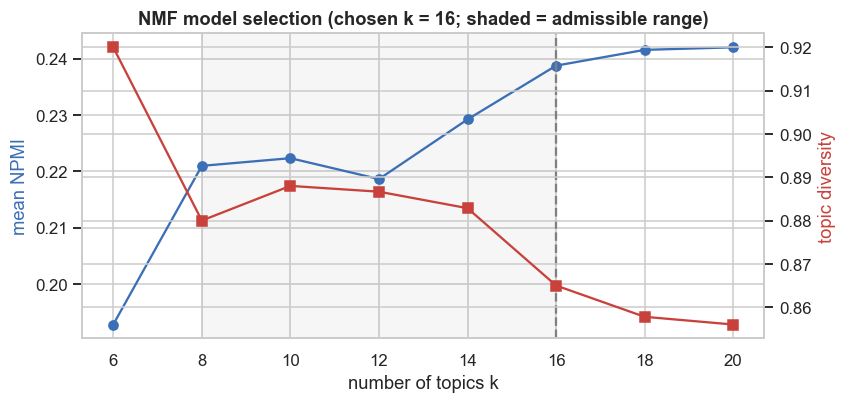

In [29]:
tfidf = TfidfVectorizer(tokenizer=str.split, token_pattern=None, lowercase=False, ngram_range=(1, 2), min_df=5, max_df=0.5,
                        max_features=12_000, sublinear_tf=True)
X = tfidf.fit_transform(core["lemmas"])
vocab = np.array(tfidf.get_feature_names_out())
Xb = (X > 0).astype(np.float32).tocsc()
UNIGRAM = np.array([" " not in v for v in vocab])
print(f"Document-term matrix: {X.shape[0]:,} documents × {X.shape[1]:,} terms (uni- and bigrams), density {X.nnz / np.prod(X.shape):.2%}")

def npmi_coherence(H, top_n=10):
    N = Xb.shape[0]
    scores = []
    for comp in H:
        idx = [i for i in np.argsort(comp)[::-1] if UNIGRAM[i]][:top_n]
        sub = Xb[:, idx]
        df_w = np.asarray(sub.sum(axis=0)).ravel()
        co = (sub.T @ sub).toarray()
        vals = []
        for a in range(len(idx)):
            for b in range(a + 1, len(idx)):
                p_ab = co[a, b] / N
                if p_ab == 0:
                    vals.append(-1.0)
                elif p_ab >= 1:
                    vals.append(1.0)
                else:
                    vals.append(math.log(p_ab / ((df_w[a] / N) * (df_w[b] / N))) / -math.log(p_ab))
        scores.append(float(np.mean(vals)))
    return np.array(scores)

def topic_diversity(H, top_n=25):
    tops = [np.argsort(c)[::-1][:top_n] for c in H]
    return len({i for t in tops for i in t}) / (top_n * len(H))

t0 = time.time()
grid, nmf_models = [], {}
for k in K_GRID:
    nmf = NMF(n_components=k, init="nndsvda", random_state=SEED, max_iter=600)
    W = nmf.fit_transform(X)
    coh = npmi_coherence(nmf.components_)
    nmf_models[k] = (nmf, W, coh)
    grid.append({"k": k, "npmi_mean": coh.mean(), "npmi_min": coh.min(), "diversity": topic_diversity(nmf.components_),
                 "reconstruction_error": nmf.reconstruction_err_})
grid = pd.DataFrame(grid)
eligible = grid[grid["k"].between(*K_SELECT_RANGE) & (grid["diversity"] >= 0.75)]
K_FINAL = int((eligible if len(eligible) else grid).sort_values(["npmi_mean", "k"], ascending=[False, True]).iloc[0]["k"])
display(save_table(grid.round(4), "11_nmf_model_selection"))
print(f"Selected k = {K_FINAL} ({time.time() - t0:.0f}s for the grid)")
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(grid["k"], grid["npmi_mean"], "-o", color="#3b6fb6", label="NPMI coherence")
ax.set_xlabel("number of topics k"); ax.set_ylabel("mean NPMI", color="#3b6fb6")
ax2 = ax.twinx(); ax2.plot(grid["k"], grid["diversity"], "-s", color="#c8423b", label="topic diversity"); ax2.set_ylabel("topic diversity", color="#c8423b")
ax.axvline(K_FINAL, color="grey", ls="--"); ax.axvspan(*K_SELECT_RANGE, color="grey", alpha=0.07)
ax.set_title(f"NMF model selection (chosen k = {K_FINAL}; shaded = admissible range)")
save_fig(fig, "13_topic_model_selection")

In [30]:
t0 = time.time()
cv = CountVectorizer(tokenizer=str.split, token_pattern=None, lowercase=False, ngram_range=(1, 2), vocabulary=tfidf.vocabulary_)
Xc = cv.fit_transform(core["lemmas"])
lda = LatentDirichletAllocation(n_components=K_FINAL, learning_method="batch", max_iter=40, random_state=SEED)
W_lda = lda.fit_transform(Xc)
coh_lda = npmi_coherence(lda.components_)
nmf_final, W_nmf, coh_nmf = nmf_models[K_FINAL]
comparison = pd.DataFrame([
    {"model": f"NMF (TF-IDF), k={K_FINAL}", "npmi_mean": coh_nmf.mean(), "npmi_min": coh_nmf.min(), "diversity": topic_diversity(nmf_final.components_)},
    {"model": f"LDA (counts), k={K_FINAL}", "npmi_mean": coh_lda.mean(), "npmi_min": coh_lda.min(), "diversity": topic_diversity(lda.components_)},
])
display(save_table(comparison.round(4), "11_nmf_vs_lda"))
MAIN = "NMF" if comparison.at[0, "npmi_mean"] >= comparison.at[1, "npmi_mean"] else "LDA"
print(f"LDA fitted in {time.time() - t0:.0f}s. Main model for the analysis: {MAIN} (higher mean NPMI).")
lda_top = pd.DataFrame({f"LDA topic {t + 1}": [vocab[i] for i in np.argsort(c)[::-1][:8]] for t, c in enumerate(lda.components_)})
display(lda_top.T.head(K_FINAL))

,model,npmi_mean,npmi_min,diversity
0,"NMF (TF-IDF), k=16",0.2387,0.1028,0.865
1,"LDA (counts), k=16",0.1556,0.0338,0.685


LDA fitted in 23s. Main model for the analysis: NMF (higher mean NPMI).


,0,1,2,3,4,5,6,7
LDA topic 1,people,google,human,find,learn,start,project,write
LDA topic 2,cloud,google,inference,gpu,deploy,gemini,platform,deployment
LDA topic 3,prompt,dataset,document,file,example,api,token,language
LDA topic 4,startup,innovation,industry,infrastructure,global,approach,ecosystem,market
LDA topic 5,nvidia,gpu,cloud,hat,platform,blackwell,inference,enterprise
LDA topic 6,agent,enterprise,platform,business,ai agent,customer,security,service
LDA topic 7,united_states,china,chinese,chip,government,deepseek,trump,country
LDA topic 8,agent,qwen,token,claude,api,cod,anthropic,context
LDA topic 9,deepseek,r1,reasoning,deepseek r1,answer,reasoning_model,o1,learning
LDA topic 10,gpu,token,inference,compute,memory,energy,hardware,efficiency


,topic,docs_dominant,mean_share,npmi,top_terms,representative_titles
0,T01 reasoning · reinforcement · reinforcement learning,52,0.057,0.242,"reasoning, reinforcement, reinforcement learning, r1, learning, deepseek r1, chain_of_thought, reward, mat...",How test-time scaling unlocks hidden reasoning abilities in small language model ‖ Understanding Reasoning...
1,T02 deepseek · r1 · chinese,103,0.077,0.309,"deepseek, r1, chinese, china, united_states, chip, deepseek r1, tech, chinese ai, liang, nvidia, market",What is DeepSeek and why did US tech stocks fall? ‖ How Chinese company DeepSeek released a top AI reasoni...
2,T03 blackwell · gpu · workload,53,0.054,0.258,"blackwell, gpu, workload, inference, nvidia, cloud, nvl72, rack, data_center, google cloud, infrastructure...","10 Big Nvidia GTC 2025 Announcements: Blackwell Ultra, Rubin Ultra, DGX Spark An ‖ NVIDIA Unveils Next-Gen..."
3,T04 claude · agent · cod,127,0.084,0.204,"claude, agent, cod, anthropic, kimi, opus, agentic, frontier, token, benchmark, open_weight, glm","The Best LLMs for Agentic Coding in 2026 (Real-World, Not Just Benchmarks) ‖ Cursor bets on cheaper coding..."
4,T05 memory · attention · token,75,0.060,0.231,"memory, attention, token, kv, cache, transformer, sequence, layer, kv cache, parameter, weight, gpu",DeepSeek-V3 Explained 1: Multi-head Latent Attention ‖ Optimizing inference ‖ A Visual Guide to Attention ...
5,T06 image · video · text,59,0.056,0.215,"image, video, text, visual, generation, multimodal, image generation, text image, stable_diffusion, conten...",Blythe Doll AI Generator ‖ Qolaba AI ‖ AI & Parametric Negotiation 2.0
6,T07 china · united_states · chinese,81,0.064,0.416,"china, united_states, chinese, trump, administration, government, american, country, trump administration,...",China's Xi calls for global AI rules amid US tech restrictions ‖ Trump administration vows crackdown on Ch...
7,T08 nemotron · nvidia · nvidia nemotron,63,0.046,0.363,"nemotron, nvidia, nvidia nemotron, agent, nemo, cosmos, ai agent, dgx, nvidia ai, physical ai, nim, physical",Nvidia’s Nemotron model families will advance AI agents ‖ NVIDIA Announces Nemotron Model Families to Adva...
8,T09 gemma · gemma model · model gemma,26,0.034,0.184,"gemma, gemma model, model gemma, jax, safety, pathways, evaluation, google, tpu, jax ml, ml pathways, text",google/gemma-3-270m-it · Hugging Face ‖ google/gemma-3-12b-it · Hugging Face ‖ Gemma 3n model card
9,T10 api · file · python,105,0.078,0.184,"api, file, python, request, endpoint, prompt, command, response, sdk, rag, manage, project",Deploy and inference Gemma using Model Garden and Gemini Enterprise Agent Platfo ‖ Use models in Model Gar...


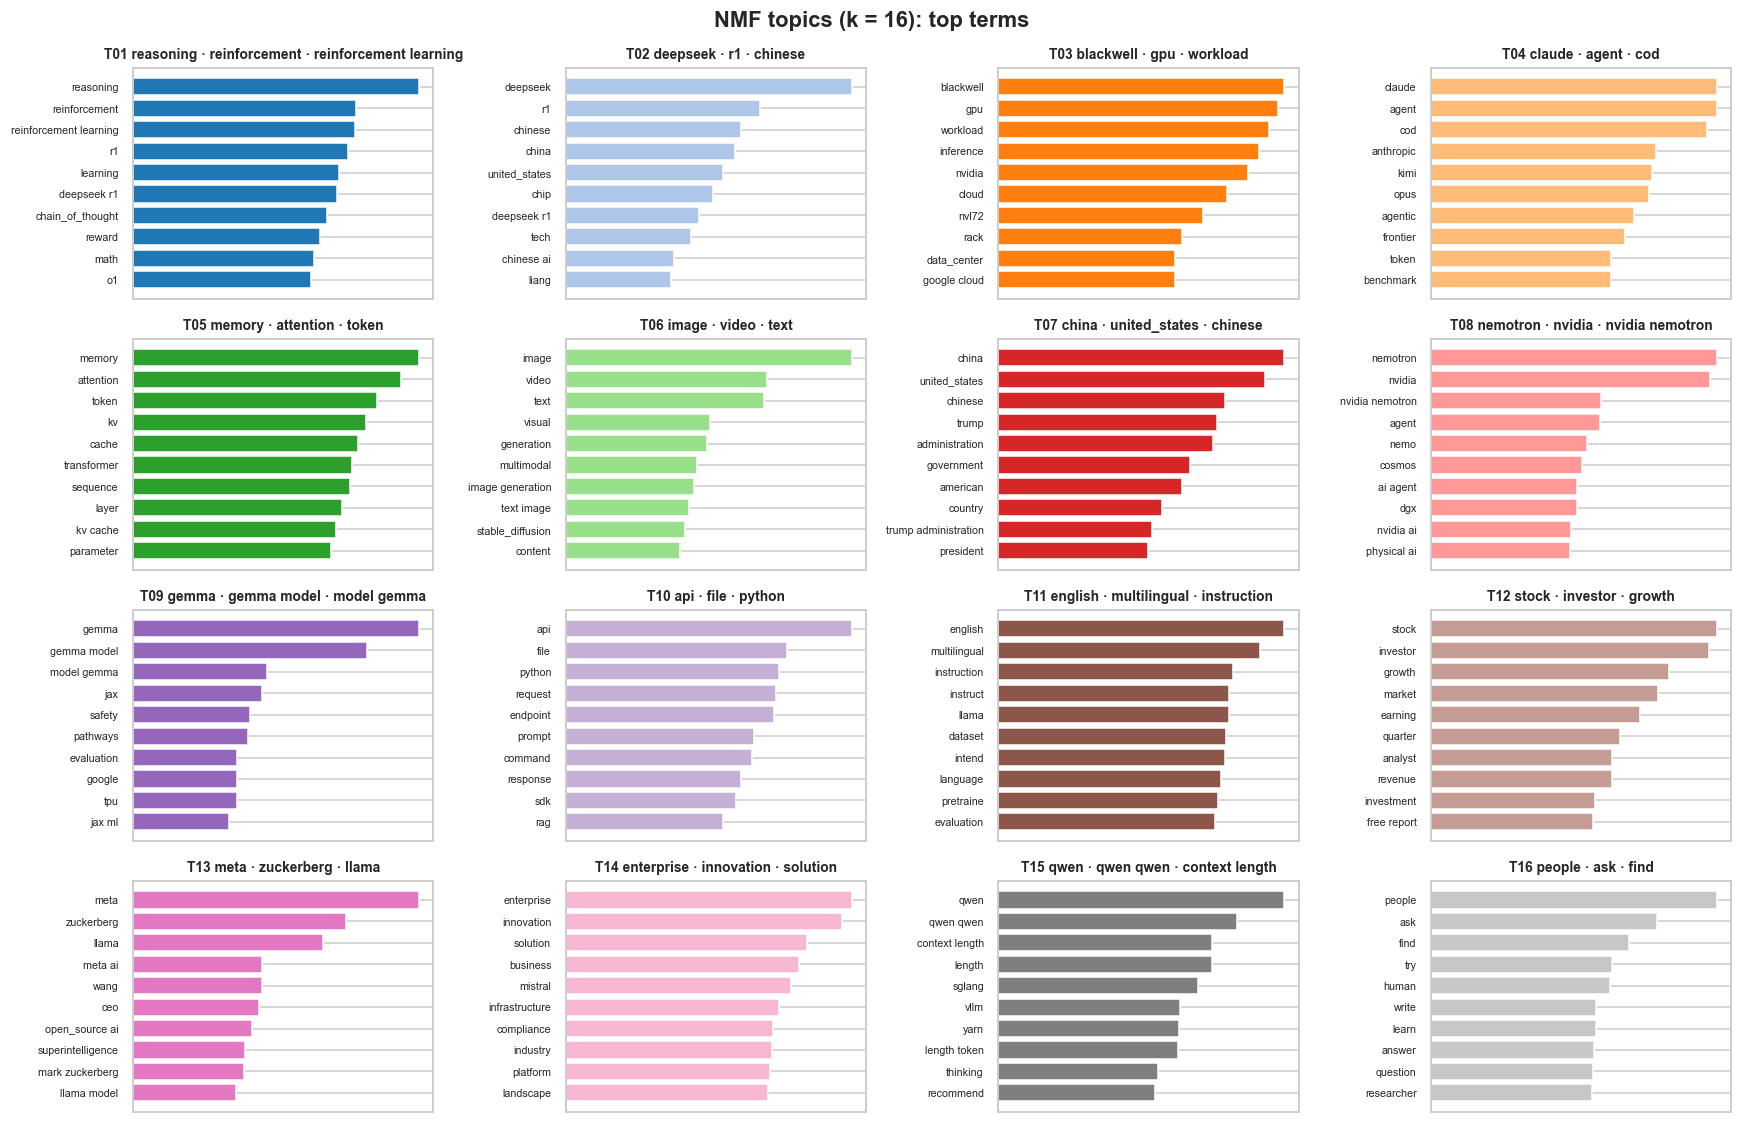

In [31]:
W_main, H_main, coh_main = (W_nmf, nmf_final.components_, coh_nmf) if MAIN == "NMF" else (W_lda, lda.components_, coh_lda)
row_sum = W_main.sum(axis=1, keepdims=True)
Wn = np.divide(W_main, row_sum, out=np.zeros_like(W_main), where=row_sum > 0)
top_terms = [[vocab[i] for i in np.argsort(c)[::-1][:12]] for c in H_main]
TOPIC_LABELS = [f"T{t + 1:02d} " + " · ".join(tt[:3]) for t, tt in enumerate(top_terms)]
core["dominant_topic"] = np.where(row_sum.ravel() > 0, Wn.argmax(axis=1), -1)
topic_tab = pd.DataFrame({
    "topic": TOPIC_LABELS,
    "docs_dominant": np.bincount(core["dominant_topic"][core["dominant_topic"] >= 0], minlength=K_FINAL),
    "mean_share": Wn.mean(axis=0).round(3), "npmi": coh_main.round(3),
    "top_terms": [", ".join(t) for t in top_terms],
    "representative_titles": [" ‖ ".join(core["title"].iloc[np.argsort(Wn[:, t])[::-1][:3]].str[:80]) for t in range(K_FINAL)],
})
display(save_table(topic_tab, "11_topics"))

n_cols = 4
n_rows = math.ceil(K_FINAL / n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 2.6 * n_rows))
for t, ax in enumerate(axes.ravel()):
    if t >= K_FINAL:
        ax.axis("off"); continue
    idx = np.argsort(H_main[t])[::-1][:10]
    ax.barh(vocab[idx][::-1], H_main[t][idx][::-1], color=sns.color_palette("tab20", K_FINAL)[t])
    ax.set_title(TOPIC_LABELS[t], fontsize=9); ax.tick_params(labelsize=7); ax.set_xticks([])
fig.suptitle(f"{MAIN} topics (k = {K_FINAL}): top terms", fontweight="bold")
fig.tight_layout()
save_fig(fig, "14_topic_terms")

**Q4 · Model selection and topics.**
* **Choice of *k*:** coherence generally rises with *k*. In the admissible range (8–16) the rule picks *k* = 16 (NPMI 0.239, topic diversity 0.87); *k* = 14 scores 0.229.
* **NMF vs LDA:** at the same *k*, NMF clearly outperforms LDA (NPMI 0.239 vs 0.156, diversity 0.87 vs 0.69), so NMF is the main model.
* **The 16 topics** (names are ours; the T-numbers refer to this run) fall into six groups:

| Group | Topics |
|---|---|
| **Market and geopolitics** | T02 *deepseek · r1 · chinese*: the DeepSeek shock in the news (US tech stocks, chips, China)<br>T12 *stock · investor · growth*: stock-market and investor coverage<br>T07 *china · united_states · chinese*: US–China policy (Trump administration, Beijing's response) |
| **Developer strategies** | T13 *meta · zuckerberg · llama*: Meta's Llama strategy, including reports that Meta is moving away from open releases<br>T08 *nemotron · nvidia*: NVIDIA's open model families<br>T14 *enterprise · innovation · solution*: enterprise adoption, Mistral, Europe's AI independence |
| **Models and their internals** | T01 *reasoning · reinforcement learning*: reasoning models and RL (DeepSeek R1 explainers)<br>T05 *memory · attention · token*: architectures and inference (multi-head latent attention, KV cache)<br>T11 *english · multilingual · instruction*: Llama model cards and instruct variants<br>T09 *gemma*: Gemma model cards<br>T15 *qwen*: Qwen model cards and serving |
| **Agents and developer use** | T04 *claude · agent · cod*: open models (Kimi, GLM) in coding agents, compared with Claude<br>T10 *api · file · python*: running and calling models (APIs, Model Garden, RAG) |
| **Infrastructure and applications** | T03 *blackwell · gpu · workload*: GPUs and inference infrastructure<br>T06 *image · video · text*: generative image and video tools (Stable Diffusion) |
| **Residual** | T16 *people · ask · find*: general and research writing, weakest coherence (NPMI 0.10) |

### 11.1 Topic dynamics
Topic prevalence is the mean topic share of the documents in a period, a soft count that does not force each article into a single topic. Monthly values are noisy at about 50 core documents per month, so the heat map uses quarters. The trend is the slope of a linear fit to monthly prevalence, in percentage points per year. We also compare year 1 (Sep 2024–Aug 2025) with year 2 (Sep 2025–Aug 2026).

,slope_pp_per_year,year1_share,year2_share,change_pp
key,,,,
T04 claude · agent · cod,9.86,4.46,13.15,8.69
T08 nemotron · nvidia · nvidia nemotron,3.40,2.88,7.40,4.52
T07 china · united_states · chinese,2.97,4.61,7.01,2.40
T10 api · file · python,1.92,7.19,8.94,1.75
T15 qwen · qwen qwen · context length,1.13,2.70,3.90,1.20
T03 blackwell · gpu · workload,0.43,5.17,6.01,0.85
T09 gemma · gemma model · model gemma,0.26,3.76,3.83,0.08
T16 people · ask · find,-0.12,10.76,11.37,0.61
T05 memory · attention · token,-0.30,6.46,6.52,0.06


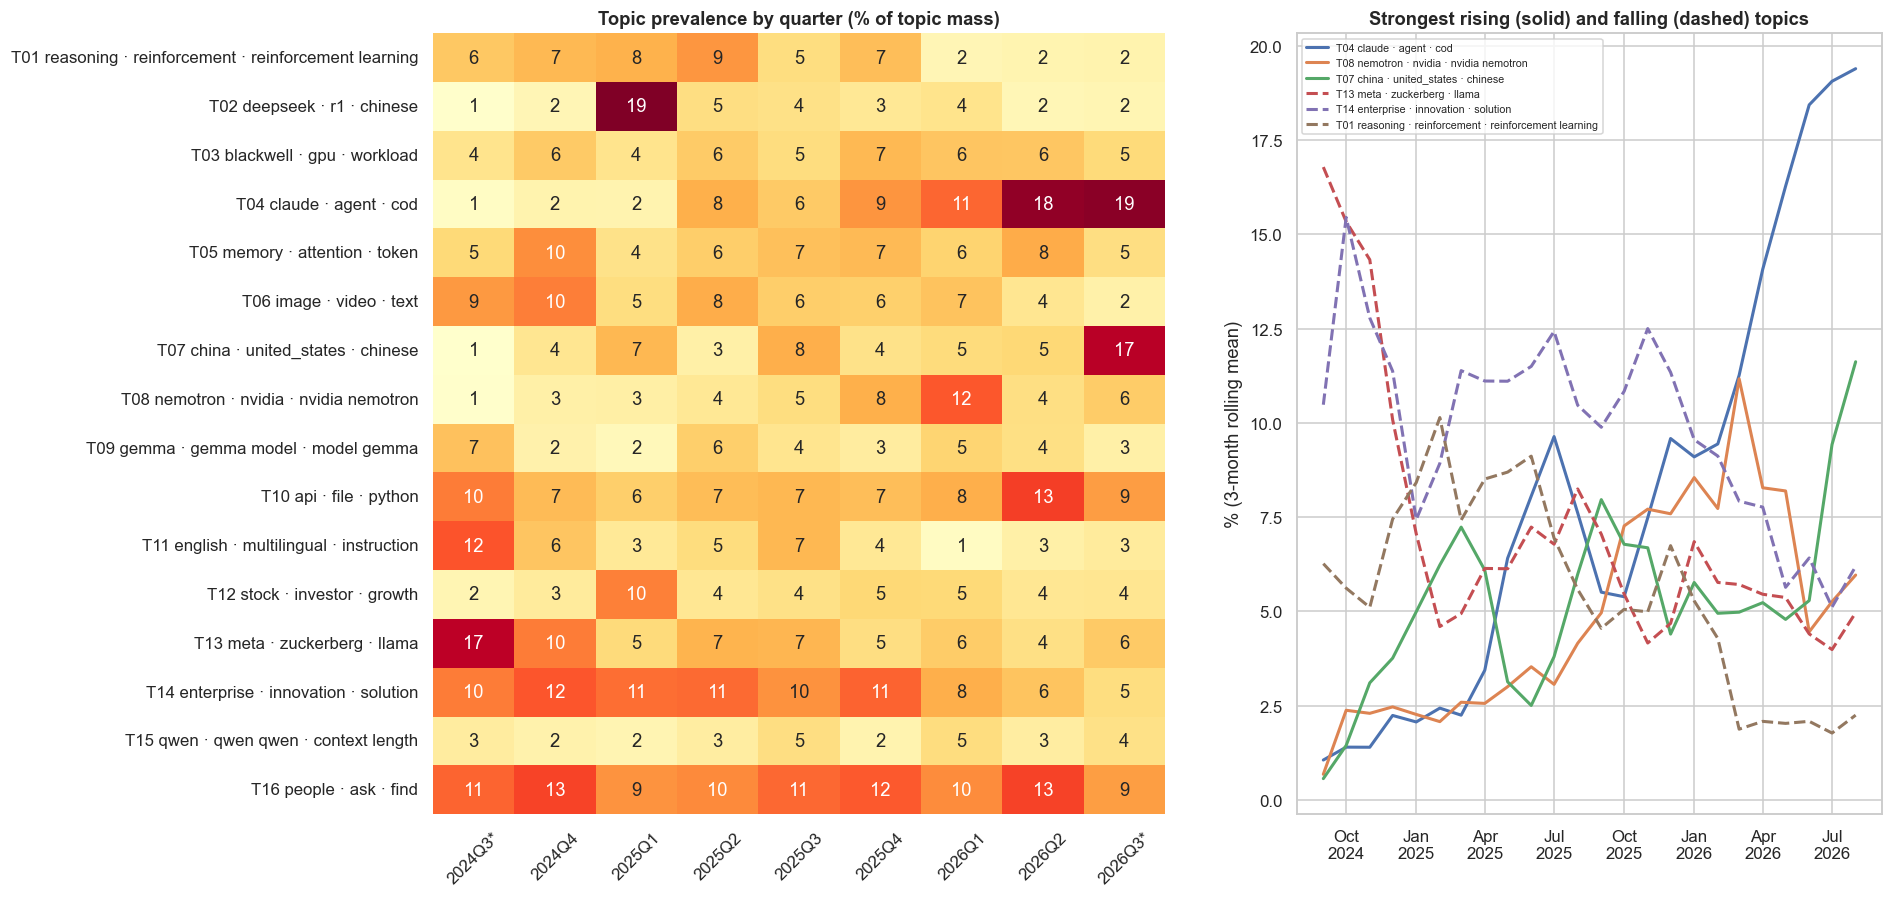

In [32]:
prev_q = pd.DataFrame(Wn, columns=TOPIC_LABELS).groupby(core["quarter"].to_numpy()).mean() * 100
prev_m = pd.DataFrame(Wn, columns=TOPIC_LABELS).groupby(core["month"].to_numpy()).mean() * 100
months_sorted = sorted(prev_m.index)
prev_m = prev_m.loc[months_sorted]
slope = {t: np.polyfit(np.arange(len(prev_m)), prev_m[t].to_numpy(), 1)[0] * 12 for t in TOPIC_LABELS}
trend = pd.DataFrame({"slope_pp_per_year": pd.Series(slope), "year1_share": prev_m.iloc[:12].mean(), "year2_share": prev_m.iloc[12:].mean()})
trend["change_pp"] = trend["year2_share"] - trend["year1_share"]
trend = trend.sort_values("slope_pp_per_year", ascending=False).round(2)
display(save_table(trend, "11_topic_trends", index=True)); save_table(prev_q.round(2), "11_topic_prevalence_quarterly", index=True)

fig, axes = plt.subplots(1, 2, figsize=(17, 0.42 * K_FINAL + 2.5), gridspec_kw={"width_ratios": [1.25, 1]})
sns.heatmap(prev_q.T, annot=True, fmt=".0f", cmap="YlOrRd", ax=axes[0], cbar=False)
axes[0].set_xticklabels([q + ("*" if q in PARTIAL_Q else "") for q in prev_q.index], rotation=45)
axes[0].set_title("Topic prevalence by quarter (% of topic mass)"); axes[0].set_ylabel(""); axes[0].set_xlabel("")
xm = pd.to_datetime(pd.Index(months_sorted) + "-01")
movers = list(trend.index[:3]) + list(trend.index[-3:])
for t in movers:
    axes[1].plot(xm, prev_m[t].rolling(3, min_periods=1).mean(), lw=2, label=t, ls="-" if t in trend.index[:3] else "--")
axes[1].set_ylabel("% (3-month rolling mean)"); axes[1].set_title("Strongest rising (solid) and falling (dashed) topics")
axes[1].legend(fontsize=7); axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
save_fig(fig, "15_topic_dynamics")

**Q4 · How the themes move.** The clearest shift is from *what open models are* to *what they are used for*. Shares are topic mass in year 1 → year 2.
* **Rising:**
  * agentic coding (T04) is the strongest riser: 4.5 % → 13.2 % (+9.9 percentage points per year);
  * NVIDIA's Nemotron ecosystem (T08): 2.9 % → 7.4 %;
  * US–China policy (T07): 4.6 % → 7.0 %;
  * deployment and API usage (T10): 7.2 % → 8.9 %.
* **Falling:**
  * reasoning models and RL (T01): 7.4 % → 3.4 %, and the DeepSeek news topic (T02): 7.0 % → 2.9 %, both after their early-2025 peak;
  * Meta's Llama strategy (T13): 8.3 % → 5.1 %;
  * the enterprise and business topic (T14): 10.8 % → 8.4 %;
  * generative image and video tools (T06): 7.5 % → 4.8 %;
  * Llama model cards (T11): 6.1 % → 2.7 %.

The 2025 wave was about Chinese reasoning models and their market shock. The 2026 wave is about open models as workhorses for agents, measured against closed frontier models, while Meta, the early leader in open models, receives less attention.

## 12. Key insights and limitations
1. **Open models are a small but persistent slice of AI coverage.** 2–3 % of documents are core and 6–10 % mention open models. The share tripled during the DeepSeek shock (January–February 2025, about 6 %) and rose again in mid-2026 (3.8 % in July).
2. **The discourse became a US–China story.** Chinese families went from 0.2 mentions per US-family mention (Q4 2024) to parity or above from Q1 2025, and lead again in July–August 2026 (Kimi, GLM, Qwen).
3. **Releases drive attention, and the release cadence accelerated.** Coverage peaks follow major releases (DeepSeek R1, Llama 4, Kimi K2, gpt-oss). In 2026, Qwen 3.5/3.6, Gemma 4, DeepSeek V4, Kimi K3 and GLM-5.x arrive within months of each other.
4. **The vocabulary is becoming more precise.** *Open-weight* grew from about 10 % to 40–60 % of openness mentions.
5. **Framing differs by origin.** Chinese models are framed through geopolitics and cost, US and European ones through enterprise adoption and access. Explicit safety framing is rare.
6. **The theme moved from the models to their use.** Agentic coding and NVIDIA's open-model ecosystem rise, while the 2025 reasoning-model and image-generation topics recede.

**Limitations**
* **Lexicon-based track definition.**
  * Precision of the core tier is high (92 % relevant), but the validation sample is small (n = 40) and the labels were AI-assisted from titles and openings.
  * Families outside the lexicon (new labs, renamed models) are missed until they are added.
* **Corpus composition.** The dataset is a curated crawl with undocumented inclusion criteria, and source volumes change over time. Trends are therefore reported as shares, but absolute volumes still reflect collection choices, and some core documents are developers' own announcements and documentation.
* **Dates.** Document dates are publication or crawl dates. Some catalogue and documentation pages carry dates older than their content, as the first-seen dates of gpt-oss and Qwen 3 show. Event dates must come from the text.
* **Sentiment and framing are dictionary-based** (VADER and keyword frames). They are transparent and reproducible, but they miss irony, negation scope and domain meaning.
* **Topic models are unstable at the margins.** With 1,210 documents, small topics such as Qwen (26 dominant documents) are partly model-card artefacts. Topic numbers and names refer to this run (`random_state = 42`, scikit-learn 1.9.1). With scikit-learn 1.8.0 the same rule selects *k* = 14: the themes are largely the same, but at *k* = 16 the DeepSeek topic splits into a news and a reasoning-model topic, and Meta's Llama strategy becomes a topic of its own. `requirements.txt` therefore pins scikit-learn.
* **English only.** The pipeline handles English; the 357 non-English documents are excluded.


## 13. Outputs and hand-over
All outputs are written below and described in `artifacts/stage1_wp1/data_dictionary.md`.

In [33]:
df_out = df
df_out.to_parquet(CLEAN_PATH, index=False)
core_out = core[["doc_id", "date", "month", "quarter", "domain", "url", "title", "text", "om_score", "om_families", "om_regions",
                 "lemmas", "dominant_topic"]].copy()
core_out["dominant_topic_label"] = [TOPIC_LABELS[t] if t >= 0 else None for t in core_out["dominant_topic"]]
core_out["topic_weights"] = [list(map(float, r)) for r in Wn.round(4)]
core_out.to_parquet(DATA_PROCESSED / "open_models_core.parquet", index=False)
sent_df.to_parquet(DATA_PROCESSED / "open_models_target_sentences.parquet", index=False)

lexicon_export = {
    "version": "wp1-1.0", "created_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "note": "Regexes are applied to the matching view (Section 6). 'kw' are literal pre-filter triggers; family ids are canonical identities.",
    "families": FAMILIES, "concepts": CONCEPTS, "ecosystem": ECOSYSTEM, "frames": FRAMES,
    "version_patterns": [[f, rx.pattern, fmt] for f, rx, fmt in VERSION_PATTERNS],
    "phrase_normalisation": [[rx.pattern, rep.strip()] for rx, rep in PHRASES],
    "relevance_score": "3*title_hit + 2*lead_hit + min(openness_concepts, 4) + 0.5*min(family_mentions, 6); core if >= 4; API reference pages form the separate tier reference",
}
(LEXDIR / "open_models_lexicon.json").write_text(json.dumps(lexicon_export, indent=2, ensure_ascii=False), encoding="utf-8")

LOG["track"] = {"tiers": {k: int(v) for k, v in df["om_tier"].value_counts().items()}, "core_score_min": CORE_SCORE_MIN,
                "target_sentences": int(len(sent_df))}
LOG["topics"] = {"main_model": MAIN, "k": K_FINAL, "labels": TOPIC_LABELS, "npmi_mean": float(coh_main.mean())}
LOG["last_run_utc"] = datetime.now(timezone.utc).isoformat(timespec="seconds")
LOG_PATH.write_text(json.dumps(LOG, indent=2, ensure_ascii=False, default=str), encoding="utf-8")

DATA_DICTIONARY = {
    "corpus_clean.parquet": (df_out, {
        "doc_id": "stable id: 'doc_' + first 10 hex chars of sha1(url)", "src_row": "index column of the raw Kaggle CSV (pointer to the source row)",
        "date": "publication date (datetime)", "month": "YYYY-MM", "quarter": "YYYYQn", "domain": "source (publisher) as given in the raw data",
        "url": "article URL", "title": "repaired title", "text": "fidelity text: repaired, NFC, boilerplate removed, paragraphs separated by a blank line",
        "tags": "dataset entity tags (list)", "n_paras": "paragraphs kept", "n_paras_removed": "paragraphs removed as boilerplate or empty",
        "n_chars": "characters of `text`", "n_words": "whitespace tokens of `text`", "en_sw_ratio": "share of English stop words (language heuristic)",
        "dup_cluster_size": "number of copies of this story before deduplication (1 = unique)",
        "om_tier": "open-models relevance tier: core / reference / mention / none", "is_api_reference": "True for API reference pages with code signatures (tier reference if they mention open models)", "om_score": "relevance score (Section 7.2)",
        "om_families": "open-model family ids mentioned (list)", "om_regions": "developer regions of the mentioned families (list)"}),
    "open_models_core.parquet": (core_out, {
        "doc_id": "see above", "date": "publication date", "month": "YYYY-MM", "quarter": "YYYYQn", "domain": "source", "url": "article URL",
        "title": "repaired title", "text": "fidelity text", "om_score": "relevance score", "om_families": "family ids mentioned",
        "om_regions": "developer regions", "lemmas": "analysis view used for topic modelling (space-separated)",
        "dominant_topic": "index of the topic with the largest share (-1 if empty)", "dominant_topic_label": "automatic label of that topic",
        "topic_weights": f"normalised topic shares from the {MAIN} model (list of {K_FINAL} floats)"}),
    "open_models_target_sentences.parquet": (sent_df, {
        "doc_id": "document id", "date": "publication date", "sent_idx": "sentence position in the document (rule-based split)",
        "sentence": "sentence text (matching view: ASCII quotes and hyphens)", "families": "family ids found in the sentence",
        "concepts": "openness concepts found in the sentence", "vader_compound": "VADER compound sentiment (-1..1)",
        **{f: "frame keyword present (bool)" for f in FRAMES}, "quarter": "YYYYQn", "regions": "developer regions of the families"}),
}
lines = ["# Data dictionary: Stage 1 · WP1 outputs", "",
         f"Generated by `notebooks/stage1_wp1_data_topic_analysis.ipynb` on {datetime.now(timezone.utc).date()}. "
         f"Raw snapshot `{RAW_CSV.name}` (sha256 `{RAW_SHA[:16]}…`). Lexicon: `artifacts/stage1_wp1/lexicon/open_models_lexicon.json`.", ""]
for fname, (frame, cols) in DATA_DICTIONARY.items():
    undocumented = [c for c in frame.columns if c not in cols]
    assert not undocumented, f"{fname}: undocumented columns {undocumented}"
    lines += [f"## `data/processed/{fname}` ({len(frame):,} rows)", "", "| column | description |", "|---|---|"]
    lines += [f"| `{c}` | {cols[c]} |" for c in frame.columns] + [""]
(DOCS / "data_dictionary.md").write_text("\n".join(lines), encoding="utf-8")

for folder in [DATA_PROCESSED, OUT]:
    for p in sorted(folder.rglob("*")):
        if p.is_file():
            print(f"{p.relative_to(REPO_ROOT)}  ({p.stat().st_size / 1e6:.2f} MB)")

data\processed\corpus_clean.parquet  (250.05 MB)
data\processed\lemma_cache.parquet  (3.01 MB)
data\processed\open_models_core.parquet  (10.33 MB)
data\processed\open_models_target_sentences.parquet  (1.33 MB)
data\processed\track_scan_cache.parquet  (0.75 MB)
artifacts\stage1_wp1\data_dictionary.md  (0.00 MB)
artifacts\stage1_wp1\figures\01_boilerplate_by_source.png  (0.05 MB)
artifacts\stage1_wp1\figures\02_cleaning_funnel.png  (0.05 MB)
artifacts\stage1_wp1\figures\03_volume_and_length.png  (0.05 MB)
artifacts\stage1_wp1\figures\04_sources.png  (0.11 MB)
artifacts\stage1_wp1\figures\05_track_share_monthly.png  (0.17 MB)
artifacts\stage1_wp1\figures\06_family_ranking.png  (0.12 MB)
artifacts\stage1_wp1\figures\07_family_heatmap.png  (0.06 MB)
artifacts\stage1_wp1\figures\08_regions_quarterly.png  (0.11 MB)
artifacts\stage1_wp1\figures\09_release_radar.png  (0.15 MB)
artifacts\stage1_wp1\figures\10_terminology.png  (0.15 MB)
artifacts\stage1_wp1\figures\11_sentiment.png  (0.12 MB)
art